# 📊 Analisis Customer Churn: SambungHome

## Executive Summary
Notebook ini menganalisis customer churn pada **SambungHome** *(perusahaan fiktif)*, penyedia layanan internet rumah di Indonesia, menggunakan dataset publik IBM Telco Customer Churn sebanyak 7.032 pelanggan setelah cleaning.

**Masalah:** 26,6% pelanggan (1.869 pelanggan) berhenti berlangganan, paling banyak terjadi di 6 bulan pertama dan pada pelanggan dengan kontrak month-to-month.

**Tujuan utama:** mengidentifikasi pelanggan yang paling berisiko churn, faktor-faktor yang berhubungan dengan churn, dan menyusun rekomendasi retensi yang spesifik dan dapat diuji.

**Dataset:** IBM Telco Customer Churn<br>
**Target:** `Churn`<br>
**Metode:** Data Cleaning, EDA, Statistical Testing (chi-square, Cramér's V, Mann-Whitney U), dan Risk Segmentation (rule-based)<br>
**Rekomendasi:** **SambungHome SHIELD**, empat lapis perlindungan dari churn: Paket Komitmen (kontrak 1 tahun), Auto-Pay Switch, Protection Starter Pack (Online Security + Tech Support), dan Risk Score Priority List<br>
**Target (1 tahun):** setiap kelompok berisiko diarahkan mendekati performa kelompok pembanding yang lebih baik di data SambungHome sendiri (*benchmark internal*), sehingga churn keseluruhan turun di bawah 26,6%

# 1. Business Understanding

## 1.1 Konteks Bisnis
SambungHome *(perusahaan fiktif dalam studi kasus ini)* adalah penyedia layanan internet rumah yang beroperasi di Indonesia. Layanan utamanya adalah koneksi internet rumah melalui jaringan Fiber Optic maupun DSL, yang dapat dilengkapi dengan telepon rumah dan berbagai layanan tambahan seperti Online Security, Online Backup, Device Protection, Tech Support, serta Streaming TV dan Movies. Pelanggan membayar tagihan setiap bulan, dengan pilihan untuk berlangganan secara bulanan tanpa ikatan (*month-to-month*) atau terikat kontrak selama 1 atau 2 tahun. Dengan model ini, kesehatan bisnis SambungHome sangat bergantung pada seberapa lama pelanggan bertahan, karena setiap bulan pelanggan tetap berlangganan berarti satu bulan tambahan pendapatan bagi perusahaan.

## 1.2 Latar Belakang
Kebutuhan akan internet rumah di Indonesia masih jauh dari titik jenuh. Survei APJII 2025 mencatat bahwa 80,66% penduduk Indonesia, atau sekitar 229,4 juta jiwa, sudah terhubung ke internet (ANTARA, 2025). Akan tetapi, sebagian besar akses tersebut masih melalui jaringan seluler, karena rumah tangga yang memiliki internet tetap (*fixed broadband*) baru sekitar 21%. Pemerintah, melalui Kementerian Komunikasi dan Digital, menargetkan angka tersebut meningkat menjadi 50% pada tahun 2029 (Bisnis.com, 2025). Kondisi ini membuka peluang besar bagi penyedia internet rumah, sekaligus membuat persaingan untuk merebut rumah tangga baru semakin ketat.

Namun, pertumbuhan jumlah pelanggan baru tidak banyak berarti apabila pelanggan lama terus berhenti berlangganan. Gallo (2014) dalam *Harvard Business Review* menyebutkan bahwa mendapatkan satu pelanggan baru dapat menghabiskan biaya 5 hingga 25 kali lebih besar dibandingkan mempertahankan pelanggan yang sudah ada. Bagi perusahaan berbasis langganan seperti SambungHome, menjaga pelanggan agar tetap bertahan menjadi cara yang lebih hemat untuk ikut tumbuh bersama pasar.

## 1.3 Problem Statement
Data pelanggan SambungHome menunjukkan bahwa 1.869 dari 7.032 pelanggan, atau 26,58%, telah berhenti berlangganan. Artinya, lebih dari satu dari setiap empat pelanggan meninggalkan perusahaan. Pelanggan yang berhenti juga cenderung pergi lebih cepat: median masa berlangganan mereka hanya 10 bulan, dibandingkan 38 bulan pada pelanggan yang bertahan. Setiap pelanggan yang pergi lebih awal harus digantikan oleh pelanggan baru, yang biayanya jauh lebih mahal untuk didapatkan.

Saat ini, SambungHome belum mengetahui secara pasti pada tahap mana pelanggan paling rentan untuk pergi, karakteristik apa yang membedakan mereka, dan kelompok mana yang perlu ditangani lebih dulu. Tanpa informasi tersebut, upaya retensi berisiko dilakukan secara merata kepada semua pelanggan, sehingga biayanya tinggi tetapi hasilnya tidak terukur. Oleh karena itu, analisis ini bertujuan untuk mengidentifikasi pelanggan yang paling berisiko churn beserta faktor-faktor yang berhubungan dengan churn, lalu menerjemahkannya menjadi tindakan retensi yang spesifik, terarah, dan dapat diuji.


**Sumber:**
- APJII via ANTARA (2025). https://www.antaranews.com/berita/5019229/apjii-catat-tingkat-penetrasi-internet-indonesia-capai-8066-persen
- Komdigi via Bisnis.com (2025). https://teknologi.bisnis.com/read/20251001/101/1916328/komdigi-targetkan-penetrasi-fixed-broadband-naik-dari-21-menjadi-50-pada-2029
- Gallo, A. (2014). *The Value of Keeping the Right Customers*. Harvard Business Review.


Meskipun masalah ini berdampak besar, perusahaan **belum memiliki pemahaman yang cukup** mengenai:
- Karakteristik pelanggan yang paling rentan churn
- Layanan dan kontrak yang paling berkaitan dengan churn
- Kelompok pelanggan mana yang harus diprioritaskan dalam program retensi
- Periode kritis di mana intervensi paling dibuutuhkan

Tanpa pemahaman ini, upaya retensi pelanggan tidak dapat dilakukan secara efektif dan tepat sasaran, sehingga perusahaan terus menanggung kerugian yang seharusnya dapat dicegah



## 1.4 Main Question
> **Pelanggan mana yang harus SambungHome targetkan dengan tawaran retensi, dan kapan, untuk menurunkan churn rate?**

## 1.5 Research Questions
Setiap pertanyaan memakai variabel dan uji yang berbeda, dan diakhiri dengan **"so that"**, yaitu keputusan bisnis yang didukungnya.

| RQ | Pertanyaan | Variabel · Metode | So that… |
|---|---|---|---|
| **RQ1** (G1) | Berapa churn rate keseluruhan dan berapa jumlah pelanggan yang hilang? Apakah pelanggan yang churn berbeda dari yang bertahan dalam hal tenure dan tingkat tagihan? | Churn, MonthlyCharges, tenure · Mann-Whitney U | kita punya baseline untuk semua target |
| **RQ2** (G2) | Apakah pelanggan baru (0–6 bulan) lebih banyak churn daripada pelanggan lama? Di setiap kelompok tenure, bagaimana jenis kontrak mengubah churn, dan segmen tenure × kontrak mana yang menyumbang churn terbanyak? | TenureGroup, Contract · chi-square, Cramér's V | kita tahu siapa yang ditawari upgrade kontrak, dan kapan |
| **RQ3** (G3) | Dari 18 atribut pelanggan, mana yang berhubungan signifikan dengan churn dan seberapa kuat? Apakah pembayar Electronic Check tetap lebih banyak churn di jenis kontrak yang sama? Apakah pelanggan internet tanpa Online Security dan Tech Support lebih banyak churn? | Semua atribut · ranking chi-square + Cramér's V | kita hanya bertindak pada atribut yang relevan dan bisa diubah |
| **RQ4** (G4) | Bisakah atribut terkuat digabung menjadi satu risk score? Seperti apa profil pelanggan high-risk dan berapa porsi churn yang mereka sumbang? | RiskScore 6 flag · churn rate per skor, porsi yang tertangkap | tim retensi punya daftar prioritas |

## 1.6 Goals (dalam 1 tahun setelah implementasi)

Target ditetapkan dengan pendekatan **benchmark internal**: setiap kelompok berisiko diarahkan agar churn-nya **mendekati kelompok pembanding yang sudah lebih baik** di data SambungHome sendiri. Angka baseline dan benchmark seluruhnya berasal dari hasil analisis RQ1–RQ4, tanpa proyeksi atau model. Besarnya penurunan yang sebenarnya diukur melalui pilot.

| Goal | Kelompok sasaran | Baseline (churn) | Benchmark internal | Arah target |
|---|---|---|---|---|
| **G1** | Seluruh pelanggan | 26,6% (1.869 dari 7.032) | – | Churn keseluruhan turun di bawah baseline |
| **G2** | Pelanggan baru (0–6 bulan) dengan kontrak month-to-month | 55,2% (1.413 pelanggan) | Month-to-month secara umum: 42,7% (RQ2) | Churn mendekati rata-rata month-to-month |
| **G3a** | Pembayar Electronic Check dengan kontrak month-to-month | 53,7% (1.850 pelanggan) | Metode otomatis di kontrak yang sama: 32,8–34,1% (RQ3) | Churn mendekati pembayar otomatis |
| **G3b** | Pelanggan internet tanpa Online Security dan Tech Support | 49,0% (2.553 pelanggan) | Memiliki salah satu add-on: 21,8% (RQ3) | Churn mendekati pelanggan dengan minimal satu add-on |
| **G4** | Pelanggan High Risk | 67,7% (1.012 pelanggan) | Medium Risk: 37,6% (RQ4) | 100% dihubungi dalam 30 hari; churn mendekati Medium Risk |

**Keterangan:**
- **Benchmark internal** dipilih karena kelompok pembandingnya benar-benar ada di data SambungHome, sehingga arah target realistis untuk dicapai.
- Keberhasilan diukur dengan membandingkan pelanggan yang menerima tawaran (*offered group*) dan yang tidak (*comparison group*) selama pilot.
- **Timeline:** bulan 1–3 pilot pada pelanggan High Risk, bulan 4–6 diperluas ke Medium Risk, bulan 7–12 ke seluruh pelanggan yang memenuhi syarat (detail di bagian 10).

## 1.7 Scope
- **Dalam cakupan:** seluruh 7.032 pelanggan, 16 atribut kategorikal + 3 numerik, uji statistik dan risk score rule-based.
- **Di luar cakupan:** pembuktian sebab-akibat, model machine learning atau regresi, data kualitas jaringan/komplain/pemakaian (tidak tersedia), perubahan harga.
  
## Stakeholder
**Primary Stakeholder: Customer Retention Manager**
Customer Retention Manager adalah pihak yang bertanggung jawab 
merancang dan mengeksekusi strategi untuk mempertahankan pelanggan 
yang sudah ada agar tidak berpindah ke kompetitor.

**Peran dan tanggung jawab:**
* Merancang program retensi pelanggan berbasis data
* Menentukan segmen pelanggan yang perlu diprioritaskan untuk intervensi
* Mengalokasikan anggaran kampanye retensi secara efisien
* Memantau KPI retensi seperti churn rate, retention rate, dan tingkat penerimaan tawaran.
* Berkoordinasi dengan tim produk untuk perbaikan layanan yang berkaitan 
  dengan churn

**Manfaat hasil analisis untuk stakeholder:**
Hasil analisis ini akan memberikan Customer Retention Manager:
* **Profil pelanggan berisiko tinggi** yang dapat langsung digunakan 
  sebagai target intervensi
* **Faktor-faktor kunci** yang paling berkaitan dengan churn sehingga 
  program retensi dapat difokuskan pada penyebab utama
* **Segmentasi risiko** berdasarkan karakteristik pelanggan untuk 
  prioritisasi kampanye yang lebih efisien
* **Rekomendasi aksi** yang terukur dan didukung data statistik sebagai 
  dasar pengambilan keputusan bisnis

# 2. Import Library

In [48]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, mannwhitneyu, chi2_contingency
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

# Warna (dipakai di seluruh notebook)
HI = "#D9692A"      # oranye: yang disorot / churn
CTX = "#9DBEE3"     # biru muda: pembanding / bertahan
NAVY = "#14213D"    # navy: garis median & teks
PALETTE_CHURN = {"No": CTX, "Yes": HI}
COLOR_ACCENT = HI

print("✅  Library berhasil dimuat.")

✅  Library berhasil dimuat.


# 3. Load Dataset

In [49]:
FILE_PATH = "Telco Customer Churn.csv"
df = pd.read_csv(FILE_PATH)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset: IBM Telco Customer Churn (dataset publik), 7.043 baris × 21 kolom.

# 4. Data Understanding

In [50]:
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")
print(f"Duplikasi    : {df.duplicated().sum():,}")
df.info()

Jumlah baris : 7,043
Jumlah kolom : 21
Duplikasi    : 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null  

## 4.1 Data Dictionary

In [51]:
data_dictionary = pd.DataFrame([
    ("Demografi", "gender", "Kategorikal", "Jenis kelamin pelanggan"),
    ("Demografi", "SeniorCitizen", "Biner (0/1)", "Pelanggan lansia atau bukan"),
    ("Demografi", "Partner", "Biner (Yes/No)", "Memiliki pasangan"),
    ("Demografi", "Dependents", "Biner (Yes/No)", "Memiliki tanggungan"),
    ("Akun", "customerID", "ID", "ID unik pelanggan"),
    ("Akun", "tenure", "Numerik (bulan)", "Lama berlangganan"),
    ("Akun", "Contract", "Kategorikal (3)", "Month-to-month, One year, Two year"),
    ("Akun", "PaperlessBilling", "Biner (Yes/No)", "Tagihan tanpa kertas"),
    ("Akun", "PaymentMethod", "Kategorikal (4)", "Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic)"),
    ("Akun", "MonthlyCharges", "Numerik (USD/bulan)", "Tagihan bulanan"),
    ("Akun", "TotalCharges", "Numerik (USD)", "Total tagihan selama berlangganan"),
    ("Layanan", "PhoneService", "Biner (Yes/No)", "Layanan telepon"),
    ("Layanan", "MultipleLines", "Kategorikal (3)", "Lebih dari satu saluran telepon"),
    ("Layanan", "InternetService", "Kategorikal (3)", "DSL, Fiber optic, No"),
    ("Layanan", "OnlineSecurity", "Kategorikal (3)", "Add-on keamanan online"),
    ("Layanan", "OnlineBackup", "Kategorikal (3)", "Add-on backup online"),
    ("Layanan", "DeviceProtection", "Kategorikal (3)", "Add-on proteksi perangkat"),
    ("Layanan", "TechSupport", "Kategorikal (3)", "Add-on dukungan teknis"),
    ("Layanan", "StreamingTV", "Kategorikal (3)", "Add-on streaming TV"),
    ("Layanan", "StreamingMovies", "Kategorikal (3)", "Add-on streaming film"),
    ("Target", "Churn", "Biner (Yes/No)", "Yes = berhenti berlangganan, No = bertahan"),
], columns=["Kelompok", "Kolom", "Tipe", "Deskripsi"])
display(data_dictionary)

,Kelompok,Kolom,Tipe,Deskripsi
0,Demografi,gender,Kategorikal,Jenis kelamin pelanggan
1,Demografi,SeniorCitizen,Biner (0/1),Pelanggan lansia atau bukan
2,Demografi,Partner,Biner (Yes/No),Memiliki pasangan
3,Demografi,Dependents,Biner (Yes/No),Memiliki tanggungan
4,Akun,customerID,ID,ID unik pelanggan
5,Akun,tenure,Numerik (bulan),Lama berlangganan
6,Akun,Contract,Kategorikal (3),"Month-to-month, One year, Two year"
7,Akun,PaperlessBilling,Biner (Yes/No),Tagihan tanpa kertas
8,Akun,PaymentMethod,Kategorikal (4),"Electronic check, Mailed check, Bank transfer ..."
9,Akun,MonthlyCharges,Numerik (USD/bulan),Tagihan bulanan


## 4.2 Statistik Deskriptif

In [52]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,"7,043.00",NaN,NaN,NaN,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,"7,043.00",NaN,NaN,NaN,32.37,24.56,0.00,9.00,29.00,55.00,72.00
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.3 Missing Value dan Nilai Unik

In [53]:
summary = pd.DataFrame({
    "Dtype": df.dtypes.astype(str),
    "Missing": df.isna().sum(),
    "Blank_string": (df.astype(str).apply(lambda s: s.str.strip() == "")).sum(),
    "Unique": df.nunique(),
})
display(summary)
print("Duplikasi baris:", df.duplicated().sum())

,Dtype,Missing,Blank_string,Unique
customerID,object,0,0,7043
gender,object,0,0,2
SeniorCitizen,int64,0,0,2
Partner,object,0,0,2
Dependents,object,0,0,2
tenure,int64,0,0,73
PhoneService,object,0,0,2
MultipleLines,object,0,0,3
InternetService,object,0,0,3
OnlineSecurity,object,0,0,3


Duplikasi baris: 0


## 4.4 Distribusi Kolom Kategori

In [54]:
for col in df.select_dtypes(include="object").columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))



--- customerID ---
customerID
7590-VHVEG    1
3791-LGQCY    1
6008-NAIXK    1
5956-YHHRX    1
5365-LLFYV    1
5855-EIBDE    1
8166-ZZTFS    1
0129-KPTWJ    1
9128-CPXKI    1
9509-MPYOD    1
Name: count, dtype: int64

--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No            

### Insight

**Kolom yang perlu perhatian:**
- **customerID:** setiap nilai hanya muncul 1 kali (7.043 nilai unik untuk 7.043 baris). Artinya, kolom ini hanya berfungsi sebagai **label unik** setiap pelanggan dan tidak memiliki pola yang bisa dianalisis, sehingga tidak dipakai dalam analisis.
- **TotalCharges:** nilai yang paling sering muncul adalah **string kosong (" ") sebanyak 11 baris**. Inilah penyebab kolom ini terbaca sebagai teks (`object`), padahal seharusnya angka. Masalah ini ditangani di bagian 5.1.
- **SeniorCitizen:** masih berbentuk angka 0/1, sehingga akan diubah menjadi label "Senior" dan "Non-Senior" agar lebih mudah dibaca.
- **Churn:** masih berbentuk Yes/No, sehingga akan dibuat versi angka 1/0 (`ChurnFlag`) untuk menghitung churn rate.

**Pola dari kolom kategori:**
- Kategori **"No internet service"** muncul sebanyak **1.526** kali di enam kolom add-on (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies). Angka ini sama dengan jumlah pelanggan dengan `InternetService = No`. Artinya, data ini konsisten: pelanggan tanpa internet memang tidak bisa memakai add-on.
- Hal yang sama terjadi pada **"No phone service"** di `MultipleLines` (682), yang sama dengan jumlah pelanggan dengan `PhoneService = No`.
- **Month-to-month** adalah jenis kontrak terbanyak (3.875 pelanggan), dan **Electronic check** adalah metode pembayaran terbanyak (2.365 pelanggan).
- **Churn:** 1.869 pelanggan churn dan 5.174 bertahan, sehingga data **tidak seimbang**.
- Tidak ditemukan duplikasi baris maupun penulisan kategori yang tidak konsisten (misalnya "yes" vs "Yes"), sehingga kolom kategori tidak perlu dirapikan.

Insight Tambahan untuk Struktur Data:

**Insight Struktur Data:**

- Dataset terdiri dari **7.043 baris** (1 baris = 1 pelanggan) dan **21 kolom**, tanpa duplikasi baris.
- Semua kolom terisi penuh (**7.043 non-null**), sehingga sekilas tidak ada missing value. Namun, pengecekan lebih lanjut di bagian 4.3 menemukan 11 nilai kosong berupa spasi pada `TotalCharges`.
- Berdasarkan tipe datanya, terdapat 18 kolom bertipe teks (`object`), 2 kolom bilangan bulat (`int64`), dan 1 kolom desimal (`float64`). Tipe data ini belum sepenuhnya sesuai dengan isinya:
  - **TotalCharges** bertipe `object`, padahal isinya angka. Hal ini disebabkan oleh 11 nilai kosong, sehingga kolom ini perlu dikonversi menjadi numerik (bagian 5.1).
  - **SeniorCitizen** bertipe `int64`, padahal isinya kategori 0/1 (lansia atau bukan).
- Setelah disesuaikan dengan isinya, 21 kolom tersebut terbagi menjadi:
  - **1 kolom ID:** `customerID`
  - **1 kolom target:** `Churn`
  - **3 atribut numerik:** `tenure`, `MonthlyCharges`, `TotalCharges`
  - **16 atribut kategorikal:** 15 kolom teks lainnya ditambah `SeniorCitizen`

# 5. Data Cleaning dan Preparation

In [55]:
df_clean = df.copy()

## 5.1 Handling Total Charges

In [56]:
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
blank = df_clean[df_clean["TotalCharges"].isna()]
print(f"TotalCharges kosong: {len(blank)} baris")
print("Tenure baris tersebut:", blank["tenure"].unique())
print("Status churn baris tersebut:", blank["Churn"].value_counts().to_dict())

TotalCharges kosong: 11 baris
Tenure baris tersebut: [0]
Status churn baris tersebut: {'No': 11}


**Insight:** 11 baris kosong semuanya pelanggan baru (tenure = 0) yang belum punya tagihan, dan tidak ada yang churn. Jumlahnya hanya 0,16% data, sehingga dihapus.

## 5.2 Drop Missing dan Duplikasi

In [57]:
df_clean = df_clean.dropna(subset=["TotalCharges"]).drop_duplicates().reset_index(drop=True)
print("Shape setelah cleaning:", df_clean.shape)
print("Total missing:", df_clean.isna().sum().sum())
print("Duplikasi:", df_clean.duplicated().sum())

Shape setelah cleaning: (7032, 21)
Total missing: 0
Duplikasi: 0


## 5.3 Deteksi Outlier (IQR)

Outlier adalah nilai yang jauh berbeda dari sebagian besar data dan bisa menandakan kesalahan input. Pengecekan dilakukan dengan metode IQR (*Interquartile Range*): nilai dianggap outlier jika berada di bawah **Q1 − 1,5 × IQR** atau di atas **Q3 + 1,5 × IQR**.

Deteksi outlier hanya dilakukan pada kolom numerik kontinu, yaitu `tenure`, `MonthlyCharges`, dan `TotalCharges`. Kolom lainnya berupa kategori (misalnya `Contract`, `PaymentMethod`) atau biner 0/1 (`SeniorCitizen`), sehingga tidak dapat memiliki outlier.

In [58]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

def iqr_outlier_summary(df, columns):
    rows = []
    for col in columns:
        Q1  = df[col].quantile(0.25)
        Q3  = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lb  = Q1 - 1.5 * IQR
        ub  = Q3 + 1.5 * IQR
        n_out = int(((df[col] < lb) | (df[col] > ub)).sum())
        rows.append({"Kolom": col, "Q1": Q1, "Q3": Q3, "IQR": IQR,
                     "Lower Bound": lb, "Upper Bound": ub,
                     "N Outlier": n_out, "% Outlier": n_out / len(df) * 100,
                     "Min": df[col].min(), "Max": df[col].max()})
    return pd.DataFrame(rows).round(2)

outlier_summary = iqr_outlier_summary(df_clean, numeric_features)
print("── Ringkasan Outlier (Metode IQR) ──")
display(outlier_summary)

── Ringkasan Outlier (Metode IQR) ──


,Kolom,Q1,Q3,IQR,Lower Bound,Upper Bound,N Outlier,% Outlier,Min,Max
0,tenure,9.00,55.00,46.00,-60.00,124.00,0,0.00,1.00,72.00
1,MonthlyCharges,35.59,89.86,54.28,-45.82,171.27,0,0.00,18.25,118.75
2,TotalCharges,401.45,"3,794.74","3,393.29","-4,688.48","8,884.67",0,0.00,18.80,"8,684.80"


**Insight Tabel IQR:**

- **tenure**
  - IQR = 46,00 bulan (Q1 = 9,00; Q3 = 55,00).
  - Lower bound = −60,00 (tidak mungkin terjadi karena tenure tidak bisa negatif), upper bound = 124,00.
  - Nilai minimum 1 dan maksimum 72 berada di dalam batas → **0 outlier**.

- **MonthlyCharges**
  - IQR = 54,28 (Q1 = 35,59; Q3 = 89,86)
  - Lower bound = −45,82 (tidak mungkin terjadi), upper bound = 171,27.
  - Nilai minimum 18,25 dan maksimum 118,75 berada di dalam batas → **0 outlier**.
  - Rentangnya lebar karena kombinasi layanan tiap pelanggan berbeda-beda (jenis internet, telepon, dan jumlah add-on).

- **TotalCharges**
  - IQR = 3.393,29 (Q1 = 401,45; Q3 = 3.794,74).
  - Lower bound = −4.688,48 (tidak mungkin terjadi), upper bound = 8.884,67.
  - Nilai minimum 18,80 dan maksimum 8.684,80 berada di dalam batas → **0 outlier**.

**Kesimpulan:** tidak ditemukan outlier maupun nilai yang tidak wajar pada ketiga kolom, sehingga seluruh data dipertahankan. Lower bound yang negatif muncul karena data menyebar lebar, dan batas tersebut tidak berlaku karena ketiga kolom tidak mungkin bernilai negatif.

### 5.3.1 Boxplot Outlier per Fitur Numerik

Boxplot dibuat untuk **seluruh pelanggan** agar sesuai dengan perhitungan pada tabel IQR di atas.

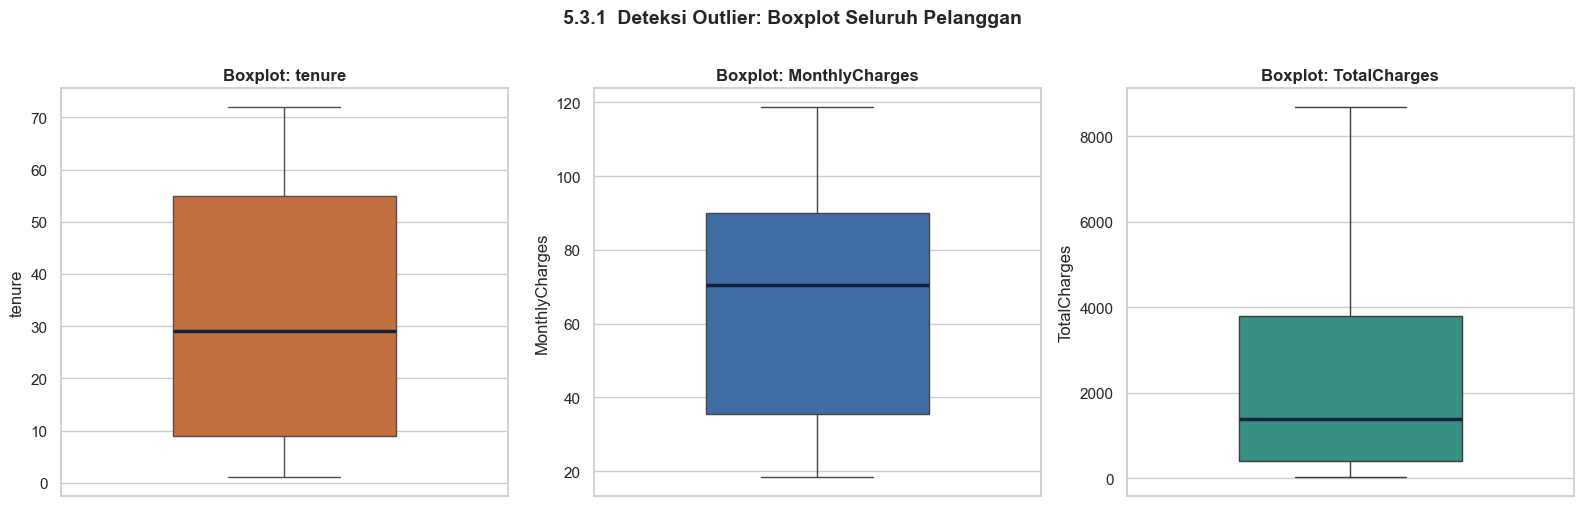

In [59]:
warna = ["#D9692A", "#2F6DB5", "#2A9D8F"]   # oranye, biru, teal
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, w in zip(axes, numeric_features, warna):
    sns.boxplot(y=df_clean[col], color=w, ax=ax, width=0.5,
                medianprops=dict(color="#14213D", linewidth=2.5))
    ax.set_title(f"Boxplot: {col}", fontsize=12, weight="bold")
    ax.set_ylabel(col)
fig.suptitle("5.3.1  Deteksi Outlier: Boxplot Seluruh Pelanggan", fontsize=14, weight="bold", y=1.01)
plt.tight_layout()
plt.savefig("plot_01_outlier_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight Boxplot Keseluruhan:**

- **tenure**
  - Median 29 bulan, dengan 50% pelanggan berada di rentang 9–55 bulan. Tidak ada titik flier.
  - Distribusinya sedikit condong ke kanan (mean 32,4 > median 29). Pelanggan cukup banyak di kedua ujung: sekitar 21% baru berlangganan ≤ 6 bulan dan sekitar 13% sudah berlangganan ≥ 67 bulan.

- **MonthlyCharges**
  - Median 70,35, dengan 50% pelanggan berada di rentang 35,59–89,86. Tidak ada titik flier.
  - Distribusinya sedikit condong ke kiri (mean 64,80 < median 70,35), karena sekitar 23% pelanggan memiliki nilai di bawah 30, yang umumnya adalah pelanggan dengan layanan lebih sedikit.

- **TotalCharges**
  - Median ≈ 1.397, dengan 50% pelanggan berada di rentang 401–3.795, dan whisker atas memanjang hingga nilai maksimum 8.684,80. Tidak ada titik flier, karena seluruh nilai masih di bawah upper bound (8.884,67).
  - Distribusinya condong ke kanan (mean 2.283 > median 1.397). Bentuk ini khas untuk variabel akumulatif, karena nilainya bertambah seiring lamanya pelanggan berlangganan, sehingga bukan indikasi kesalahan data.

**Kesimpulan:** hasil boxplot sama dengan tabel IQR, yaitu tidak ada outlier pada ketiga kolom.

### 5.3.2 Boxplot per Status Churn

Boxplot berikut memisahkan pelanggan yang bertahan (No) dan yang churn (Yes) untuk melihat gambaran awal perbedaan kedua kelompok. Pada boxplot ini, batas IQR dihitung **per kelompok**, sehingga titik yang muncul tidak sama dengan outlier pada pengecekan seluruh data.

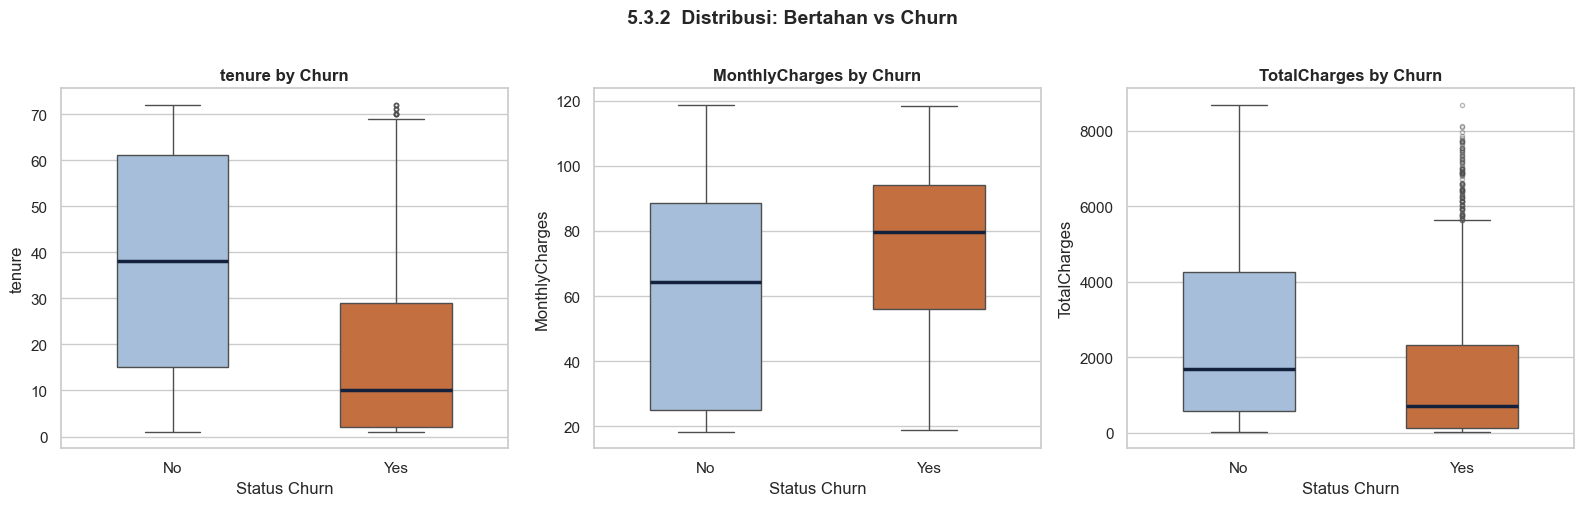

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, numeric_features):
    sns.boxplot(data=df_clean, x="Churn", y=col, hue="Churn", order=["No", "Yes"],
                palette=PALETTE_CHURN, legend=False, ax=ax, width=0.5,
                medianprops=dict(color="#14213D", linewidth=2.5),
                flierprops=dict(marker="o", alpha=0.4, markersize=3))
    ax.set_title(f"{col} by Churn", fontsize=12, weight="bold")
    ax.set_xlabel("Status Churn")
fig.suptitle("5.3.2  Distribusi: Bertahan vs Churn", fontsize=14, weight="bold", y=1.01)
plt.tight_layout()
plt.savefig("plot_02_outlier_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight Boxplot per Status Churn:**

- **tenure**
  - Bertahan: median **38 bulan**, dengan 50% pelanggan di rentang 15–61 bulan. Tidak ada titik flier.
  - Churn: median hanya **10 bulan**, dengan 50% pelanggan di rentang 2–29 bulan. Sebanyak 55% pelanggan churn pergi dalam 12 bulan pertama, dibandingkan 22% pada kelompok bertahan. Pelanggan yang churn didominasi pelanggan baru.
  - Terdapat **23 titik flier** pada kelompok churn, yaitu pelanggan dengan tenure 70–72 bulan yang tetap churn. Mereka terlihat ekstrem hanya karena kelompok churn didominasi pelanggan baru.

- **MonthlyCharges**
  - Bertahan: median **64,45**, dengan 50% pelanggan di rentang 25,10–88,47.
  - Churn: median **79,65**, dengan 50% pelanggan di rentang 56,15–94,20.
  - Box kelompok churn lebih tinggi dan lebih sempit. Pelanggan yang churn cenderung berada di tier tagihan menengah ke atas, sedangkan pelanggan yang bertahan tersebar dari tagihan rendah hingga tinggi. Tidak ada titik flier di kedua kelompok.

- **TotalCharges**
  - Bertahan: median **1.683,6**, dengan 50% pelanggan di rentang 577,8–4.264,1. Tidak ada titik flier.
  - Churn: median **703,5**, dengan 50% pelanggan di rentang 134,5–2.331,3.
  - Terdapat **109 titik flier** pada kelompok churn (nilai di atas ±5.626), yaitu pelanggan lama yang akhirnya churn. Nilai TotalCharges yang lebih rendah pada kelompok churn adalah dampak dari tenure yang pendek, bukan faktor yang terpisah.

**Kesimpulan:** titik-titik pada boxplot ini **bukan outlier yang perlu dihapus**, karena pada pengecekan seluruh data (5.3.1) semua nilai masih dalam batas wajar. Perbedaan paling jelas antara kedua kelompok ada pada **tenure**, dan perbedaan ini diuji secara statistik di RQ1 menggunakan Mann-Whitney U.

## 5.4 Export Data Clean

Data yang sudah melalui proses cleaning (penanganan missing value, pengecekan duplikasi, dan pengecekan outlier) disimpan sebagai dataset clean. Dataset ini masih berisi 21 kolom asli tanpa kolom tambahan.

In [61]:
df_clean.to_csv("Telco_Customer_Churn_Clean(remedy ver 4).csv", index=False, encoding="utf-8-sig")

print("Dataset berhasil disimpan sebagai 'Telco_Customer_Churn_Clean(remedy ver 4).csv'")
print("Jumlah baris:", len(df_clean), "| Jumlah kolom:", df_clean.shape[1])

Dataset berhasil disimpan sebagai 'Telco_Customer_Churn_Clean(remedy ver 4).csv'
Jumlah baris: 7032 | Jumlah kolom: 21


## 5.5 Feature Engineering

Feature engineering dilakukan untuk membuat kolom baru yang dibutuhkan dalam analisis RQ1–RQ4:

- **ChurnFlag**: mengubah `Churn` (Yes/No) menjadi angka 1/0, sehingga churn rate dapat dihitung sebagai rata-rata kolom ini.
- **SeniorCitizenLabel**: mengubah `SeniorCitizen` (0/1) menjadi label "Senior" dan "Non-Senior" agar tabel dan grafik lebih mudah dibaca.
- **TenureGroup**: mengelompokkan `tenure` menjadi 5 kelompok untuk melihat pada tahap mana pelanggan paling banyak churn (RQ2).
- **MonthlyChargeGroup**: membagi `MonthlyCharges` menjadi 3 tier (Low, Medium, High) dengan jumlah pelanggan yang sama, untuk membandingkan churn antar tingkat tagihan (RQ3) dan sebagai salah satu flag risk score (RQ4).

In [62]:
# 1. Target churn dalam bentuk angka
df_clean["ChurnFlag"] = (df_clean["Churn"] == "Yes").astype(int)

# 2. Label senior citizen
df_clean["SeniorCitizenLabel"] = df_clean["SeniorCitizen"].map({0: "Non-Senior", 1: "Senior"})

# 3. Kelompok masa berlangganan
TENURE_ORDER = ["0–6 bln", "7–12 bln", "13–24 bln", "25–48 bln", "49–72 bln"]
df_clean["TenureGroup"] = pd.cut(df_clean["tenure"], bins=[0, 6, 12, 24, 48, 72], labels=TENURE_ORDER)

# 4. Tier tagihan: dibagi 3 sama besar untuk SEMUA pelanggan sekaligus,
#    supaya "High" berarti tingkat tagihan yang sama untuk semua jenis internet
df_clean["MonthlyChargeGroup"] = pd.qcut(df_clean["MonthlyCharges"], q=3, labels=["Low", "Medium", "High"])

# Cek hasil
new_cols = ["ChurnFlag", "SeniorCitizenLabel", "TenureGroup", "MonthlyChargeGroup"]
print("Missing value di kolom baru:")
print(df_clean[new_cols].isna().sum().to_string())

print("\nJumlah pelanggan per TenureGroup:")
print(df_clean["TenureGroup"].value_counts(sort=False).to_string())

print("\nBatas tiap MonthlyChargeGroup:")
display(df_clean.groupby("MonthlyChargeGroup", observed=True)["MonthlyCharges"].agg(["min", "max", "count"]))

print("Shape setelah feature engineering:", df_clean.shape)

Missing value di kolom baru:
ChurnFlag             0
SeniorCitizenLabel    0
TenureGroup           0
MonthlyChargeGroup    0

Jumlah pelanggan per TenureGroup:
TenureGroup
0–6 bln      1470
7–12 bln      705
13–24 bln    1024
25–48 bln    1594
49–72 bln    2239

Batas tiap MonthlyChargeGroup:


,min,max,count
MonthlyChargeGroup,,,
Low,18.25,50.40,2345
Medium,50.45,84.00,2345
High,84.05,118.75,2342


Shape setelah feature engineering: (7032, 25)


**Insight Feature Engineering:**

- Keempat kolom baru berhasil dibuat **tanpa missing value**, dan jumlah kolom bertambah dari 21 menjadi 25.
- **ChurnFlag:** rata-rata kolom ini adalah 0,2658, sama dengan churn rate 26,58%.
- **SeniorCitizenLabel:** 1.142 pelanggan Senior dan 5.890 pelanggan Non-Senior.
- **TenureGroup:** jumlah pelanggan per kelompok adalah 1.470 (0–6 bln), 705 (7–12 bln), 1.024 (13–24 bln), 1.594 (25–48 bln), dan 2.239 (49–72 bln).
  - Batas kelompok dibuat lebih rapat di awal (6 dan 12 bulan) karena pada boxplot 5.3.2 terlihat bahwa pelanggan churn didominasi pelanggan baru (median tenure 10 bulan). Kelompok yang rapat di awal membantu melihat kapan tepatnya risiko churn paling tinggi.
  - Batas 12, 24, dan 48 bulan juga mengikuti durasi kontrak (1 tahun dan 2 tahun), sehingga mudah dipahami secara bisnis.
- **MonthlyChargeGroup:** setiap tier berisi sekitar sepertiga pelanggan, yaitu Low (18,25–50,40; 2.345 pelanggan), Medium (50,45–84,00; 2.345 pelanggan), dan High (84,05–118,75; 2.342 pelanggan). Tier ini dibaca sebagai **tingkatan relatif** (rendah, menengah, tinggi), bukan sebagai nilai uang.

> **Catatan revisi:** pada versi sebelumnya, kategori tagihan (`MonthlyChargesCategory`) dibuat secara terpisah di dalam tiap jenis internet, sehingga tier "Low" untuk Fiber Optic memiliki nilai lebih tinggi daripada tier "High" untuk DSL. Akibatnya, hasil analisis menjadi menyesatkan. Pada versi ini, `MonthlyChargeGroup` dibuat dengan batas yang sama untuk seluruh pelanggan.

## 5.6 Statistik Deskriptif (Data Clean)

Statistik deskriptif data yang sudah bersih (7.032 pelanggan) dipakai untuk memberi gambaran umum pelanggan SambungHome sebelum masuk ke analisis RQ1–RQ4.

In [63]:
# Kolom numerik
print("── Kolom Numerik ──")
display(df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T)

── Kolom Numerik ──


,count,mean,std,min,25%,50%,75%,max
tenure,"7,032.00",32.42,24.55,1.00,9.00,29.00,55.00,72.00
MonthlyCharges,"7,032.00",64.80,30.09,18.25,35.59,70.35,89.86,118.75
TotalCharges,"7,032.00","2,283.30","2,266.77",18.80,401.45,"1,397.47","3,794.74","8,684.80"


In [64]:
# Kolom kategori utama
cat_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "SeniorCitizenLabel", "Churn"]
rows = []
for col in cat_cols:
    vc = df_clean[col].value_counts()
    for val, n in vc.items():
        rows.append({"Kolom": col, "Kategori": val, "Jumlah": n,
                     "Persen (%)": round(n / len(df_clean) * 100, 1)})
print("── Kolom Kategori Utama ──")
display(pd.DataFrame(rows).set_index(["Kolom", "Kategori"]))

── Kolom Kategori Utama ──


Jumlah  Persen (%)
Kolom              Kategori                                     
Contract           Month-to-month               3875       55.10
                   Two year                     1685       24.00
                   One year                     1472       20.90
InternetService    Fiber optic                  3096       44.00
                   DSL                          2416       34.40
                   No                           1520       21.60
PaymentMethod      Electronic check             2365       33.60
                   Mailed check                 1604       22.80
                   Bank transfer (automatic)    1542       21.90
                   Credit card (automatic)      1521       21.60
PaperlessBilling   Yes                          4168       59.30
                   No                           2864       40.70
SeniorCitizenLabel Non-Senior                   5890       83.80
                   Senior                       1142       16.20
Churn              No                           5163       73.40
                   Yes                          1869       26.60

**Insight Statistik Deskriptif:**

- **Kolom numerik:** setengah pelanggan sudah berlangganan lebih dari 29 bulan (median), tetapi rentangnya lebar, dari 1 hingga 72 bulan. Detail sebaran ketiga kolom numerik sudah dibahas di bagian 5.3.
- **Contract:** mayoritas pelanggan (**55,1%**, 3.875 pelanggan) berlangganan secara bulanan (*month-to-month*), sedangkan sisanya terikat kontrak 2 tahun (24,0%) dan 1 tahun (20,9%). Artinya, lebih dari separuh pelanggan dapat berhenti kapan saja tanpa ikatan.
- **InternetService:** Fiber Optic menjadi layanan terbanyak (**44,0%**), diikuti DSL (34,4%). Sebanyak 21,6% pelanggan tidak menggunakan internet, sehingga add-on seperti Online Security dan Tech Support hanya relevan untuk 5.512 pelanggan internet.
- **PaymentMethod:** Electronic Check adalah metode pembayaran terbanyak (**33,6%**), sementara tiga metode lainnya masing-masing sekitar 22%.
- **PaperlessBilling:** 59,3% pelanggan menggunakan tagihan tanpa kertas.
- **SeniorCitizen:** sebagian besar pelanggan bukan lansia (83,8%), dan hanya 16,2% yang termasuk Senior.
- **Churn:** **26,6%** pelanggan churn (1.869 pelanggan) dan 73,4% bertahan. Karena jumlah kedua kelompok tidak seimbang, analisis selanjutnya membandingkan **churn rate per kelompok** (persentase), bukan jumlah mentah.

**Metode analisis dan tingkat signifikansi:**
- Hubungan antara churn dan atribut kategori diuji dengan **chi-square**, dan kekuatannya diukur dengan **Cramér's V** (0,1 lemah · 0,3 sedang · 0,5 kuat).
- Perbandingan kolom numerik antara pelanggan churn dan bertahan diuji dengan **Mann-Whitney U**, karena hasil uji normalitas **Shapiro-Wilk** (bagian RQ1) menentukan apakah data berdistribusi normal.
- Tingkat signifikansi yang dipakai adalah **α = 0,05**. Kesalahan kesimpulan dalam analisis ini berarti satu kampanye retensi yang kurang tepat, bukan risiko keselamatan atau investasi besar, sehingga level standar 5% sudah sesuai. Jika hasil utama memiliki p < 0,001, kesimpulannya tetap berlaku walaupun α diperketat menjadi 0,01.

## 5.7 Fungsi Bantu Analisis

Fungsi berikut dipakai berulang kali pada analisis RQ1–RQ4:
- `cramers_v`: mengukur kekuatan hubungan dua variabel kategorikal (0 = tidak ada hubungan, 1 = hubungan sempurna).
- `chi2_report`: menjalankan uji chi-square dan menampilkan p-value serta Cramér's V.
- `churn_table`: menghitung jumlah pelanggan, jumlah churn, churn rate, dan porsi dari total churn per kelompok.
- `bar_rates`: membuat bar chart churn rate dengan kelompok tertinggi disorot warna oranye.

In [65]:
def cramers_v(table):
    # Kekuatan hubungan dua variabel kategorikal (0 = tidak ada, 1 = sempurna)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

def chi2_report(data, cols, target="ChurnFlag", label=None):
    # Uji chi-square + Cramér's V antara satu/lebih kolom kategorikal dan churn
    keys = [data[c] for c in cols] if isinstance(cols, list) else data[cols]
    table = pd.crosstab(keys, data[target])
    chi2, p, dof, _ = chi2_contingency(table)
    v = cramers_v(table)
    strength = "lemah" if v < 0.3 else ("sedang" if v < 0.5 else "kuat")
    print(f"{label or cols}: chi2 = {chi2:,.1f} | p-value = {p:.2e} | Cramér's V = {v:.3f} ({strength})")
    print("→ Tolak H0: ada hubungan signifikan dengan churn" if p < 0.05
          else "→ Gagal tolak H0: tidak ada hubungan signifikan")
    return v

def churn_table(data, col, target="ChurnFlag"):
    # Jumlah pelanggan, jumlah churn, churn rate, dan porsi dari total churn per kelompok
    total_churn = data[target].sum()
    g = data.groupby(col, observed=True).agg(
        Customers=(target, "size"),
        Churned=(target, "sum"),
        Churn_Rate_pct=(target, "mean"),
    )
    g["Churn_Rate_pct"] *= 100
    g["Share_of_Churners_pct"] = g["Churned"] / total_churn * 100
    return g.round(1)

def bar_rates(series, title, xlabel="", highlight="max", ax=None, fmt="{:.1f}%"):
    # Bar chart churn rate dengan satu kelompok disorot oranye
    ax = ax or plt.gca()
    target_val = series.max() if highlight == "max" else highlight
    colors = [HI if v == target_val else CTX for v in series.values]
    ax.bar(series.index.astype(str), series.values, color=colors)
    for i, v in enumerate(series.values):
        ax.text(i, v + series.max() * 0.02, fmt.format(v), ha="center", fontsize=10,
                fontweight="bold" if v == target_val else "normal")
    ax.set_title(title, fontsize=13, fontweight="bold", loc="left")
    ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(xlabel)
    ax.set_ylim(0, series.max() * 1.18)
    return ax

print("✅  Fungsi bantu siap dipakai.")

✅  Fungsi bantu siap dipakai.


# 6. RQ1: Seberapa Besar Masalah Churn?

> Berapa churn rate keseluruhan dan berapa jumlah pelanggan yang hilang? Apakah pelanggan yang churn berbeda dari yang bertahan dalam hal tenure dan tingkat tagihan? **(G1)**

## 6.1 Churn Rate Keseluruhan

In [66]:
total_customer = len(df_clean)
total_churn = int(df_clean["ChurnFlag"].sum())
total_stay = total_customer - total_churn
churn_rate = total_churn / total_customer * 100

print(f"Total pelanggan        : {total_customer:,}")
print(f"Pelanggan churn        : {total_churn:,}")
print(f"Pelanggan bertahan     : {total_stay:,}")
print(f"Churn rate             : {churn_rate:.2f}%")
print(f"1 poin churn rate      : ± {total_customer * 0.01:.0f} pelanggan")

Total pelanggan        : 7,032
Pelanggan churn        : 1,869
Pelanggan bertahan     : 5,163
Churn rate             : 26.58%
1 poin churn rate      : ± 70 pelanggan


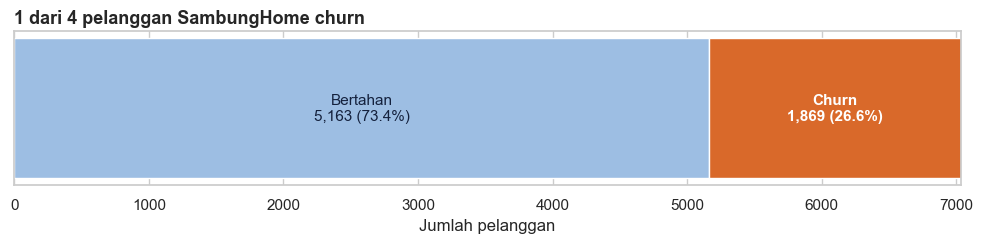

In [67]:
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.barh([0], [total_stay], color=CTX, label="Bertahan")
ax.barh([0], [total_churn], left=[total_stay], color=HI, label="Churn")
ax.text(total_stay / 2, 0, f"Bertahan\n{total_stay:,} ({100 - churn_rate:.1f}%)",
        ha="center", va="center", fontsize=11, color=NAVY)
ax.text(total_stay + total_churn / 2, 0, f"Churn\n{total_churn:,} ({churn_rate:.1f}%)",
        ha="center", va="center", fontsize=11, color="white", fontweight="bold")
ax.set_xlim(0, total_customer); ax.set_yticks([]); ax.set_xlabel("Jumlah pelanggan")
ax.set_title("1 dari 4 pelanggan SambungHome churn", fontsize=13, fontweight="bold", loc="left")
plt.tight_layout()
plt.savefig("plot_03_rq1_churn_rate.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight Churn Rate:**
- Dari 7.032 pelanggan, sebanyak **1.869 pelanggan (26,58%) churn** dan 5.163 pelanggan (73,4%) bertahan. Artinya, sekitar **1 dari 4 pelanggan** meninggalkan SambungHome.
- Setiap 1 poin churn rate setara dengan sekitar **70 pelanggan**. Angka ini dipakai untuk menerjemahkan target penurunan churn menjadi jumlah pelanggan yang dipertahankan.
- Churn rate 26,6% menjadi **baseline G1**.

## 6.2 Perbedaan Pelanggan Churn dan Bertahan (Mann-Whitney U)

Bagian 5.3.2 sudah menunjukkan secara visual bahwa pelanggan churn dan bertahan berbeda pada `tenure` dan `MonthlyCharges`. Bagian ini menguji apakah perbedaan tersebut signifikan secara statistik.

**Hipotesis:**
- H0: distribusi `tenure` (atau `MonthlyCharges`) sama antara pelanggan churn dan bertahan.
- H1: distribusinya berbeda.

**Langkah:**
1. Uji normalitas **Shapiro-Wilk** pada masing-masing kelompok (sampel 500 data, karena Shapiro-Wilk kurang akurat untuk data berukuran sangat besar). Jika p < 0,05, data tidak berdistribusi normal.
2. Jika data tidak normal, perbedaan diuji dengan **Mann-Whitney U** (uji non-parametrik).
3. Besarnya perbedaan diukur dengan **effect size r** (*rank-biserial correlation*): < 0,3 kecil · 0,3–0,5 sedang · ≥ 0,5 besar.

,Variabel,Median churn,Median bertahan,Shapiro p (churn),Shapiro p (bertahan),Mann-Whitney p,Effect size r,Kekuatan efek,Kesimpulan
0,tenure,10.00,38.00,4.2e-24,2.0e-16,6.0e-211,0.48,sedang,Tolak H0
1,MonthlyCharges,79.65,64.45,3.4e-14,3.9e-16,8.5e-54,0.24,kecil,Tolak H0


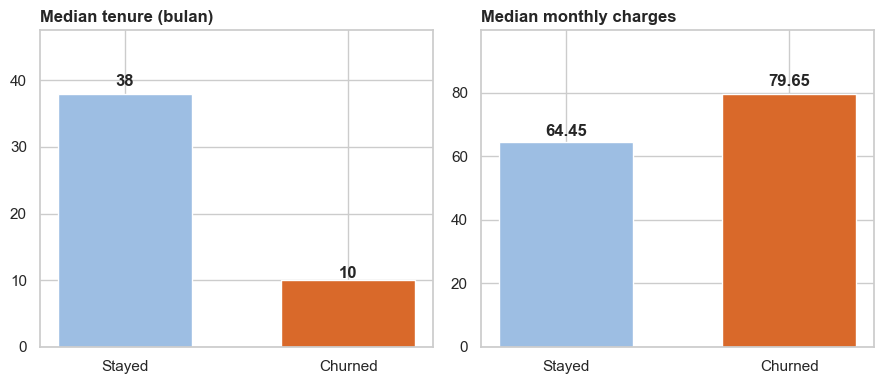

In [68]:
churned = df_clean[df_clean["ChurnFlag"] == 1]
stayed = df_clean[df_clean["ChurnFlag"] == 0]

rows = []
for col in ["tenure", "MonthlyCharges"]:
    p_norm_churn = shapiro(churned[col].sample(500, random_state=42)).pvalue
    p_norm_stay = shapiro(stayed[col].sample(500, random_state=42)).pvalue
    u, p = mannwhitneyu(churned[col], stayed[col], alternative="two-sided")
    r = abs(1 - 2 * u / (len(churned) * len(stayed)))
    effect = "kecil" if r < 0.3 else ("sedang" if r < 0.5 else "besar")
    rows.append({"Variabel": col,
                 "Median churn": churned[col].median(), "Median bertahan": stayed[col].median(),
                 "Shapiro p (churn)": f"{p_norm_churn:.1e}", "Shapiro p (bertahan)": f"{p_norm_stay:.1e}",
                 "Mann-Whitney p": f"{p:.1e}", "Effect size r": round(r, 2),
                 "Kekuatan efek": effect, "Kesimpulan": "Tolak H0" if p < 0.05 else "Gagal tolak H0"})
display(pd.DataFrame(rows))


fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (col, judul, fmt) in zip(axes, [("tenure", "Median tenure (bulan)", "{:.0f}"),
                                         ("MonthlyCharges", "Median monthly charges", "{:.2f}")]):
    vals = [stayed[col].median(), churned[col].median()]
    ax.bar(["Stayed", "Churned"], vals, color=[CTX, HI], width=0.6)
    for i, v in enumerate(vals):
        ax.text(i, v * 1.03, fmt.format(v), ha="center", fontsize=12, fontweight="bold")
    ax.set_title(judul, fontweight="bold", loc="left")
    ax.set_ylim(0, max(vals) * 1.25)
plt.tight_layout()
plt.savefig("plot_03b_rq1_median.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight Mann-Whitney U:**
- **Normalitas:** p-value Shapiro-Wilk untuk kedua variabel di kedua kelompok jauh di bawah 0,05, sehingga data **tidak berdistribusi normal**. Karena itu, uji yang dipakai adalah Mann-Whitney U.
- **tenure:** median pelanggan churn hanya **10 bulan**, dibandingkan **38 bulan** pada pelanggan bertahan. Perbedaannya **signifikan** (p < 0,001) dengan effect size **r = 0,48 (sedang, mendekati besar)**. Ini adalah perbedaan paling kuat antara kedua kelompok.
- **MonthlyCharges:** median pelanggan churn **79,65**, lebih tinggi dibandingkan **64,45** pada pelanggan bertahan. Perbedaannya juga **signifikan** (p < 0,001), tetapi effect size-nya **r = 0,24 (kecil)**. Artinya, tingkat tagihan memang berbeda, tetapi pengaruhnya jauh lebih lemah dibandingkan tenure.

### Insight → Action → Impact (RQ1)
- **Insight:** 1.869 dari 7.032 pelanggan (26,6%) churn. Pelanggan yang churn umumnya **masih baru** (median tenure 10 vs 38 bulan, efek sedang) dan berada di **tier tagihan lebih tinggi** (efek kecil).
- **Action:** karena perbedaan terbesar ada pada tenure, analisis berikutnya (RQ2) mencari **kapan tepatnya** pelanggan paling banyak churn, dan jenis kontrak apa yang memengaruhinya.
- **Impact:** setiap penurunan churn 1 poin berarti sekitar **70 pelanggan** dipertahankan. Churn rate 26,6% menjadi **baseline G1**.

# 7. RQ2: Kapan Pelanggan Churn, dan Bagaimana Peran Kontrak?

> Apakah pelanggan baru (0–6 bulan) lebih banyak churn daripada pelanggan lama? Di setiap kelompok tenure, bagaimana jenis kontrak mengubah churn, dan segmen tenure × kontrak mana yang menyumbang churn terbanyak? **(G2)**

**Hipotesis (chi-square):**
- H0: tidak ada hubungan antara `TenureGroup` (atau `Contract`) dan churn.
- H1: ada hubungan antara `TenureGroup` (atau `Contract`) dan churn.


## 7.1 Churn Berdasarkan Tenure

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
TenureGroup,,,,
0–6 bln,1470,784,53.30,41.90
7–12 bln,705,253,35.90,13.50
13–24 bln,1024,294,28.70,15.70
25–48 bln,1594,325,20.40,17.40
49–72 bln,2239,213,9.50,11.40


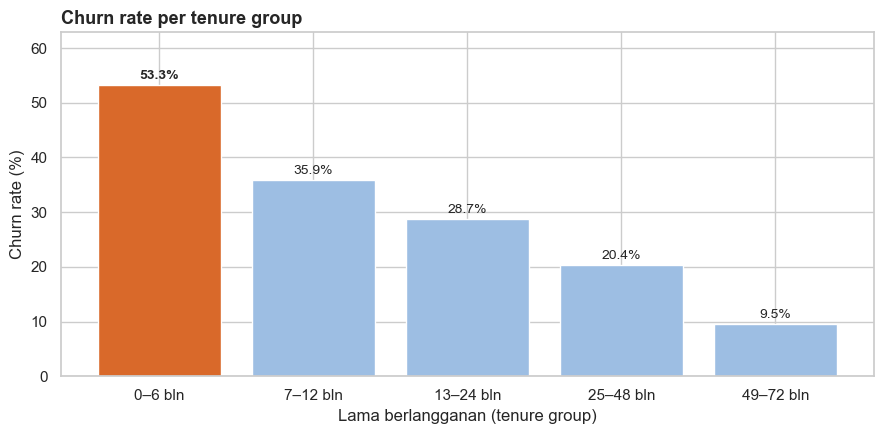

TenureGroup: chi2 = 938.3 | p-value = 8.20e-202 | Cramér's V = 0.365 (sedang)
→ Tolak H0: ada hubungan signifikan dengan churn


In [69]:
tenure_tbl = churn_table(df_clean, "TenureGroup").sort_values("Churn_Rate_pct", ascending=False)
display(tenure_tbl)

fig, ax = plt.subplots(figsize=(9, 4.5))
bar_rates(tenure_tbl["Churn_Rate_pct"], "Churn rate per tenure group",
          "Lama berlangganan (tenure group)", ax=ax)
plt.tight_layout()
plt.savefig("plot_04_rq2_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

_ = chi2_report(df_clean, "TenureGroup")

**Insight Tenure:**
- Churn rate **turun di setiap tahap tenure**: dari **53,3%** pada 0–6 bulan menjadi 35,9% (7–12 bulan), 28,7% (13–24 bulan), 20,4% (25–48 bulan), hingga hanya **9,5%** pada 49–72 bulan.
- Pelanggan 0–6 bulan hanya 1.470 orang (20,9% pelanggan), tetapi menyumbang **784 churner atau 41,9% dari seluruh churn**. Artinya, **enam bulan pertama adalah periode paling kritis**.
- Uji chi-square menunjukkan hubungan yang **signifikan** (p < 0,001) dengan **Cramér's V = 0,37 (sedang)**. Tolak H0: tenure berhubungan dengan churn.

### 7.1.1 Churn per Bulan di Tahun Pertama (Diagnostik)

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
tenure,,,,
1,613,380,62.0,36.6
2,238,123,51.7,11.9
5,133,64,48.1,6.2
4,176,83,47.2,8.0
3,200,94,47.0,9.1
7,131,51,38.9,4.9
10,116,45,38.8,4.3
9,119,46,38.7,4.4
6,110,40,36.4,3.9


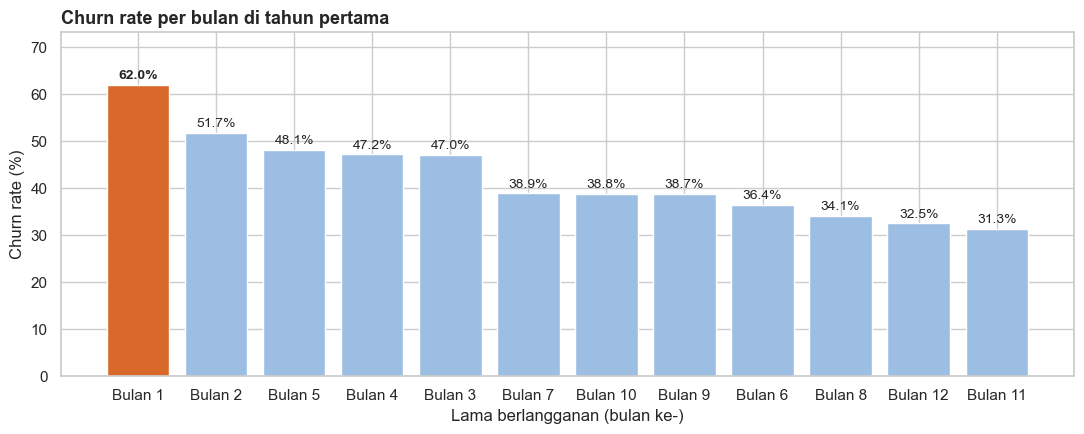

In [70]:
first_year = df_clean[df_clean["tenure"] <= 12]
month_tbl = churn_table(first_year, "tenure").sort_values("Churn_Rate_pct", ascending=False)
display(month_tbl.style.format({"Customers": "{:,.0f}", "Churned": "{:,.0f}",
                                "Churn_Rate_pct": "{:.1f}", "Share_of_Churners_pct": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(11, 4.5))
bar_rates(month_tbl["Churn_Rate_pct"].rename(index=lambda b: f"Bulan {b}"),
          "Churn rate per bulan di tahun pertama", "Lama berlangganan (bulan ke-)", ax=ax)
plt.tight_layout()
plt.savefig("plot_04b_rq2_first_year.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight Churn per Bulan:**
- Churn paling tinggi terjadi di **bulan pertama**, yaitu **62,0%** dari 613 pelanggan. Bulan pertama juga memiliki jumlah pelanggan paling banyak dibandingkan bulan-bulan lainnya di tahun pertama.
- Churn turun cukup tajam di bulan ke-2 dan ke-3 (51,7% dan 47,0%), lalu stabil di kisaran 31–48% hingga bulan ke-12.
- **Diagnosis:** risiko terbesar muncul di **30 hari pertama setelah pemasangan**, saat pelanggan baru pertama kali merasakan layanan dan menerima tagihan pertama. Karena itu, intervensi retensi sebaiknya dimulai **sejak hari pemasangan**, bukan menunggu pelanggan menunjukkan tanda akan pergi.
- Catatan: data hanya menunjukkan pola (asosiasi), sehingga penyebab pastinya (misalnya pengalaman pemasangan atau ekspektasi kecepatan) perlu dikonfirmasi lewat data komplain dan pilot.

## 7.2 Churn Berdasarkan Jenis Kontrak

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
Contract,,,,
Month-to-month,3875,1655,42.70,88.60
One year,1472,166,11.30,8.90
Two year,1685,48,2.80,2.60


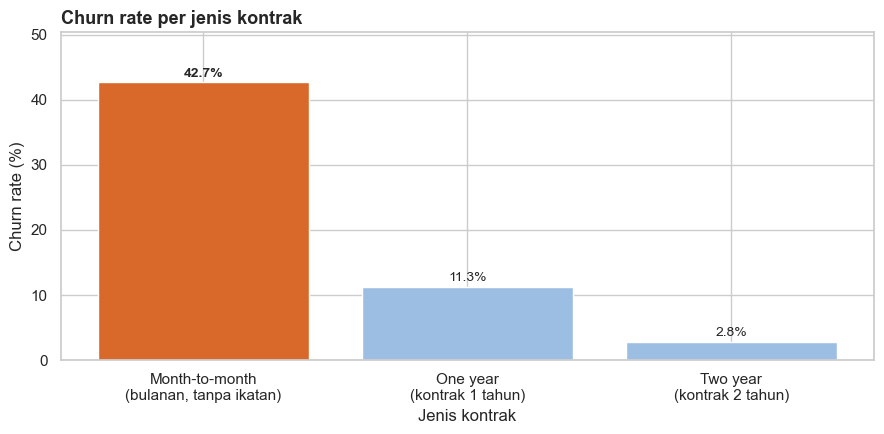

Contract: chi2 = 1,179.5 | p-value = 7.33e-257 | Cramér's V = 0.410 (sedang)
→ Tolak H0: ada hubungan signifikan dengan churn


In [71]:
CONTRACT_ORDER = ["Month-to-month", "One year", "Two year"]

contract_tbl = churn_table(df_clean, "Contract").sort_values("Churn_Rate_pct", ascending=False)
display(contract_tbl)

label_kontrak = {"Month-to-month": "Month-to-month\n(bulanan, tanpa ikatan)",
                 "One year": "One year\n(kontrak 1 tahun)",
                 "Two year": "Two year\n(kontrak 2 tahun)"}

fig, ax = plt.subplots(figsize=(9, 4.5))
bar_rates(contract_tbl["Churn_Rate_pct"].rename(index=label_kontrak), "Churn rate per jenis kontrak",
          "Jenis kontrak", ax=ax)
plt.tight_layout()
plt.savefig("plot_05_rq2_contract.png", dpi=150, bbox_inches="tight")
plt.show()

_ = chi2_report(df_clean, "Contract")

**Insight Kontrak:**
- Pelanggan **month-to-month** memiliki churn rate **42,7%**, jauh lebih tinggi dibandingkan kontrak 1 tahun (**11,3%**) dan 2 tahun (**2,8%**). Churn month-to-month sekitar **15 kali** lebih tinggi daripada kontrak 2 tahun.
- Month-to-month menyumbang **1.655 churner atau 88,6% dari seluruh churn**. Hampir semua pelanggan yang pergi adalah pelanggan tanpa ikatan kontrak.
- Uji chi-square menunjukkan hubungan yang **signifikan** (p < 0,001) dengan **Cramér's V = 0,41 (sedang)**, lebih kuat daripada tenure.

## 7.3 Tenure × Jenis Kontrak

Tenure dan kontrak saling berkaitan, karena pelanggan lama lebih banyak yang memakai kontrak panjang. Heatmap berikut memisahkan efek keduanya untuk melihat apakah kontrak tetap berpengaruh **di setiap tahap tenure**.

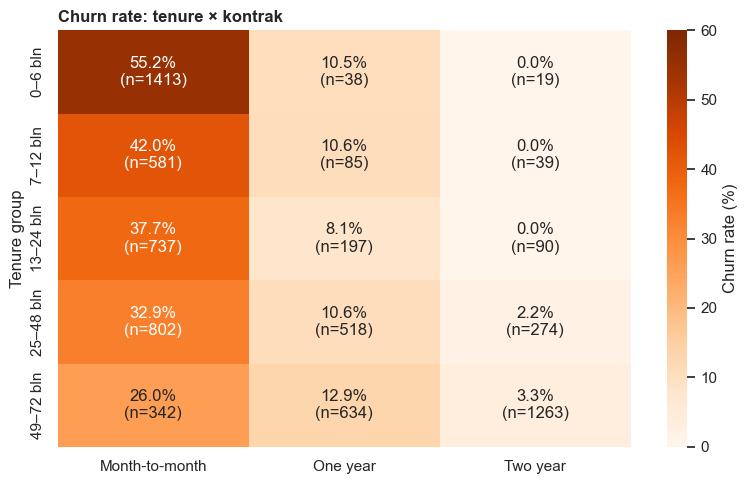

TenureGroup × Contract: chi2 = 1,393.2 | p-value = 4.82e-289 | Cramér's V = 0.445 (sedang)
→ Tolak H0: ada hubungan signifikan dengan churn
TenureGroup (hanya month-to-month): chi2 = 168.1 | p-value = 2.70e-35 | Cramér's V = 0.208 (lemah)
→ Tolak H0: ada hubungan signifikan dengan churn


In [72]:
rate = pd.crosstab(df_clean["TenureGroup"], df_clean["Contract"],
                   values=df_clean["ChurnFlag"], aggfunc="mean")[CONTRACT_ORDER] * 100
count = pd.crosstab(df_clean["TenureGroup"], df_clean["Contract"])[CONTRACT_ORDER]
annot = rate.round(1).astype(str) + "%\n(n=" + count.astype(str) + ")"

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(rate, annot=annot, fmt="", cmap="Oranges", vmin=0, vmax=60,
            cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate: tenure × kontrak", fontweight="bold", loc="left")
ax.set_ylabel("Tenure group"); ax.set_xlabel("")
plt.tight_layout()
plt.savefig("plot_06_rq2_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

_ = chi2_report(df_clean, ["TenureGroup", "Contract"], label="TenureGroup × Contract")
m2m = df_clean[df_clean["Contract"] == "Month-to-month"]
_ = chi2_report(m2m, "TenureGroup", label="TenureGroup (hanya month-to-month)")

In [73]:
# 5 segmen tenure × kontrak dengan jumlah churner terbanyak
seg = df_clean.assign(Segment=df_clean["TenureGroup"].astype(str) + " | " + df_clean["Contract"])
seg_tbl = churn_table(seg, "Segment").sort_values("Churned", ascending=False).head(5)
display(seg_tbl)

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
Segment,,,,
0–6 bln | Month-to-month,1413,780,55.20,41.70
13–24 bln | Month-to-month,737,278,37.70,14.90
25–48 bln | Month-to-month,802,264,32.90,14.10
7–12 bln | Month-to-month,581,244,42.00,13.10
49–72 bln | Month-to-month,342,89,26.00,4.80


**Insight Tenure × Kontrak:**
- **Kontrak tetap berpengaruh di setiap tahap tenure.** Pada month-to-month, churn tetap tinggi di semua tahap: 55,2% (0–6 bulan), 42,0%, 37,7%, 32,9%, hingga **26,0% bahkan setelah 4 tahun**. Sebaliknya, kontrak 1 tahun stabil di sekitar 8–13%, dan kontrak 2 tahun hanya 0–3,3%.
- **Tenure juga tetap berpengaruh di dalam kontrak yang sama.** Di antara pelanggan month-to-month saja, churn tetap turun seiring tenure (chi-square p < 0,001, Cramér's V = 0,21). Artinya, tenure dan kontrak memberi informasi yang berbeda, dan keduanya perlu dipakai.
- Gabungan tenure × kontrak memiliki hubungan **lebih kuat** dengan churn (**Cramér's V = 0,45**) dibandingkan masing-masing secara terpisah (0,37 dan 0,41).
- **Segmen paling berisiko:** pelanggan **baru (0–6 bulan) dengan kontrak month-to-month**, yaitu 1.413 pelanggan dengan churn rate **55,2%**. Segmen ini menyumbang **780 churner atau 41,7% dari seluruh churn**. Kelima segmen dengan churner terbanyak semuanya berasal dari kontrak month-to-month.
- **Catatan:** beberapa sel pada heatmap berisi sedikit pelanggan (misalnya kontrak 2 tahun di 0–6 bulan, n = 19), sehingga angkanya kurang stabil dan tidak dipakai sebagai dasar target.

### Insight → Action → Impact (RQ2)
- **Insight:** risiko churn paling tinggi di **6 bulan pertama** (53,3%) dan pada pelanggan **month-to-month** (42,7%, 88,6% dari seluruh churn). Kombinasi keduanya (0–6 bulan + month-to-month) adalah segmen paling berisiko: 55,2% churn dan 41,7% dari seluruh churner.
- **Action:** tawarkan **upgrade ke kontrak 1 tahun (R1)** kepada pelanggan month-to-month, dimulai sejak **6 bulan pertama** berlangganan.
- **Impact (G2):** churn pelanggan baru month-to-month (55,2%) diarahkan mendekati rata-rata month-to-month (42,7%). Rekomendasi lengkapnya dijelaskan di bagian 10.

# 8. RQ3: Karakteristik Pelanggan yang Berhubungan dengan Churn

> Dari 18 atribut pelanggan, mana yang berhubungan signifikan dengan churn dan seberapa kuat? Apakah pembayar Electronic Check tetap lebih banyak churn di jenis kontrak yang sama? Apakah pelanggan internet tanpa Online Security dan Tech Support lebih banyak churn? **(G3)**

**Hipotesis (chi-square), berlaku untuk setiap atribut:**
- H0: tidak ada hubungan antara atribut dan churn.
- H1: ada hubungan antara atribut dan churn.

## 8.1 Ranking Semua Atribut

Ke-18 atribut (16 atribut kategorikal asli, ditambah `TenureGroup` dan `MonthlyChargeGroup` dari feature engineering) diuji dengan cara yang sama, yaitu chi-square dan Cramér's V. Dengan begitu, atribut yang dibahas lebih lanjut dipilih berdasarkan data, bukan dipilih secara manual.

,Atribut,Chi2,p-value,Cramers_V,"Signifikan (p<0,05)",Kekuatan
0,Contract,"1,179.5",7.33e-257,0.410,Ya,sedang
1,TenureGroup,938.3,8.20e-202,0.365,Ya,sedang
2,OnlineSecurity,846.7,1.40e-184,0.347,Ya,sedang
3,TechSupport,824.9,7.41e-180,0.343,Ya,sedang
4,InternetService,728.7,5.83e-159,0.322,Ya,sedang
5,PaymentMethod,645.4,1.43e-139,0.303,Ya,sedang
6,OnlineBackup,599.2,7.78e-131,0.292,Ya,lemah
7,DeviceProtection,555.9,1.96e-121,0.281,Ya,lemah
8,StreamingMovies,374.3,5.35e-82,0.231,Ya,lemah
9,StreamingTV,372.5,1.32e-81,0.230,Ya,lemah


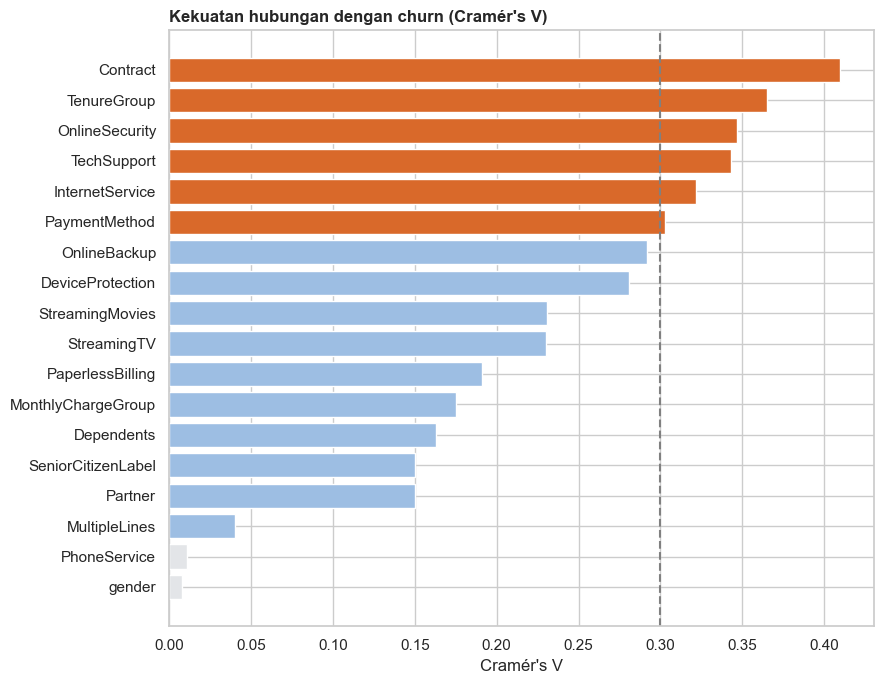

In [74]:
ATTRS = ["gender", "SeniorCitizenLabel", "Partner", "Dependents", "PhoneService", "MultipleLines",
         "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
         "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
         "TenureGroup", "MonthlyChargeGroup"]

rank = []
for col in ATTRS:
    table = pd.crosstab(df_clean[col], df_clean["ChurnFlag"])
    chi2, p, _, _ = chi2_contingency(table)
    rank.append({"Atribut": col, "Chi2": round(chi2, 1), "p-value": p,
                 "Cramers_V": round(cramers_v(table), 3)})

rank = pd.DataFrame(rank).sort_values("Cramers_V", ascending=False).reset_index(drop=True)
rank["Signifikan (p<0,05)"] = np.where(rank["p-value"] < 0.05, "Ya", "Tidak")
rank["Kekuatan"] = pd.cut(rank["Cramers_V"], [0, 0.1, 0.3, 0.5, 1],
                          labels=["sangat lemah", "lemah", "sedang", "kuat"], include_lowest=True)
rank["p-value"] = rank["p-value"].map(lambda x: f"{x:.2e}")
display(rank.style.format({"Chi2": "{:,.1f}", "Cramers_V": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 7))
colors = [HI if v >= 0.3 else (CTX if s == "Ya" else "#E3E5E8")
          for v, s in zip(rank["Cramers_V"], rank["Signifikan (p<0,05)"])]
ax.barh(rank["Atribut"], rank["Cramers_V"], color=colors)
ax.axvline(0.3, ls="--", color="grey")
ax.invert_yaxis()
ax.set_title("Kekuatan hubungan dengan churn (Cramér's V)", fontweight="bold", loc="left")
ax.set_xlabel("Cramér's V")
plt.tight_layout()
plt.savefig("plot_07_rq3_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight Ranking Atribut:**
- **Enam atribut memiliki hubungan sedang (Cramér's V ≥ 0,30)** dengan churn (batang oranye): Contract (0,41), TenureGroup (0,37), OnlineSecurity (0,35), TechSupport (0,34), InternetService (0,32), dan PaymentMethod (0,30).
- Atribut lainnya signifikan tetapi **lemah**, misalnya OnlineBackup (0,29), PaperlessBilling (0,19), MonthlyChargeGroup (0,18), serta atribut demografi seperti Dependents, SeniorCitizen, dan Partner (0,15–0,16).
- **gender (p = 0,49) dan PhoneService (p = 0,35) tidak signifikan** (gagal tolak H0). Artinya, jenis kelamin dan kepemilikan layanan telepon tidak berhubungan dengan churn, sehingga tidak dipakai untuk menargetkan pelanggan.
- Contract dan TenureGroup sudah dibahas di RQ2. Bagian berikut membahas empat atribut kuat lainnya: **PaymentMethod**, **OnlineSecurity dan TechSupport**, serta **InternetService**, ditambah MonthlyChargeGroup sebagai pembanding.

## 8.2 Metode Pembayaran × Kontrak

Pembayar Electronic Check paling banyak memakai kontrak month-to-month. Karena itu, perlu dicek apakah tingginya churn e-check hanya disebabkan oleh kontraknya, atau tetap tinggi walaupun jenis kontraknya sama.

In [75]:
pay_tbl = churn_table(df_clean, "PaymentMethod").sort_values("Churn_Rate_pct", ascending=False)
display(pay_tbl)

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
PaymentMethod,,,,
Electronic check,2365,1071,45.30,57.30
Mailed check,1604,308,19.20,16.50
Bank transfer (automatic),1542,258,16.70,13.80
Credit card (automatic),1521,232,15.30,12.40


In [76]:
pay = pd.crosstab(df_clean["PaymentMethod"], df_clean["Contract"],
                  values=df_clean["ChurnFlag"], aggfunc="mean")[CONTRACT_ORDER] * 100
display(pay.round(1))

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.10,9.70,3.40
Credit card (automatic),32.80,10.30,2.20
Electronic check,53.70,18.40,7.70
Mailed check,31.60,6.80,0.80


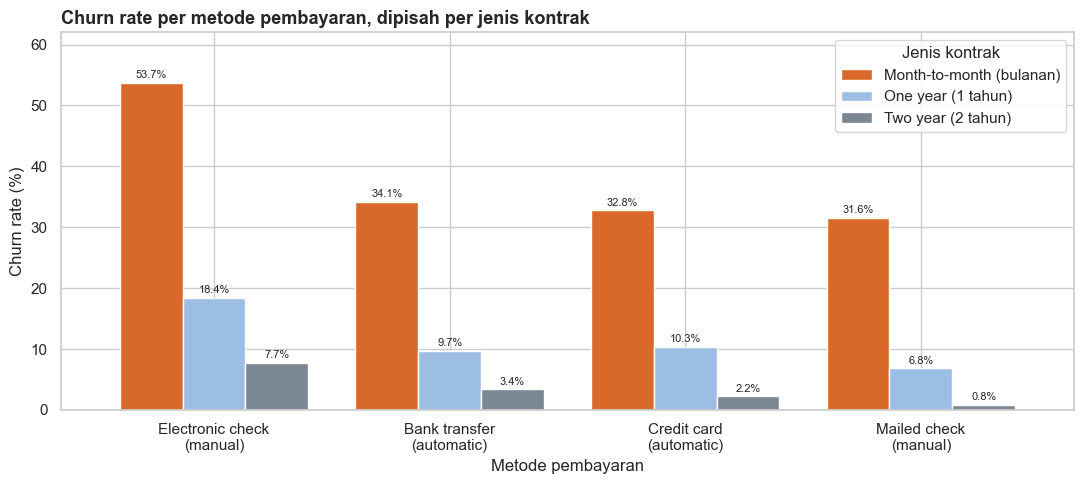

In [77]:
label_bayar = {"Electronic check": "Electronic check\n(manual)",
               "Mailed check": "Mailed check\n(manual)",
               "Bank transfer (automatic)": "Bank transfer\n(automatic)",
               "Credit card (automatic)": "Credit card\n(automatic)"}
label_kontrak = {"Month-to-month": "Month-to-month (bulanan)",
                 "One year": "One year (1 tahun)", "Two year": "Two year (2 tahun)"}

fig, ax = plt.subplots(figsize=(11, 5))
(pay.sort_values("Month-to-month", ascending=False)
    .rename(index=label_bayar, columns=label_kontrak)
    .plot(kind="bar", color=[HI, CTX, "#7C8794"], rot=0, ax=ax, width=0.8))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_title("Churn rate per metode pembayaran, dipisah per jenis kontrak", fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Metode pembayaran")
ax.set_ylim(0, 62)
ax.legend(title="Jenis kontrak")
plt.tight_layout()
plt.savefig("plot_08_rq3_payment.png", dpi=150, bbox_inches="tight")
plt.show()

In [78]:
_ = chi2_report(df_clean, "PaymentMethod")
m2m = df_clean[df_clean["Contract"] == "Month-to-month"]
_ = chi2_report(m2m, "PaymentMethod", label="PaymentMethod (hanya month-to-month)")

PaymentMethod: chi2 = 645.4 | p-value = 1.43e-139 | Cramér's V = 0.303 (sedang)
→ Tolak H0: ada hubungan signifikan dengan churn
PaymentMethod (hanya month-to-month): chi2 = 176.6 | p-value = 4.67e-38 | Cramér's V = 0.214 (lemah)
→ Tolak H0: ada hubungan signifikan dengan churn


**Insight Metode Pembayaran:**
- **Electronic Check** adalah metode dengan pelanggan **paling banyak (2.365 pelanggan)** dan sekaligus churn rate **paling tinggi (45,3%)**. Kelompok ini menyumbang **1.071 churner atau 57,3% dari seluruh churn**, lebih dari separuh pelanggan yang pergi.
- Tiga metode lainnya memiliki jumlah pelanggan yang hampir sama (1.521–1.604 pelanggan), tetapi churn rate-nya jauh lebih rendah, yaitu **19,2% (Mailed check)**, **16,7% (Bank transfer)**, dan **15,3% (Credit card)**. Walaupun jika digabung jumlahnya lebih dari dua kali e-check, ketiganya hanya menyumbang 42,7% churn.
- **Di dalam kontrak yang sama, e-check tetap paling tinggi.** Pada month-to-month, churn e-check **53,7%**, sedangkan metode lain 31,6–34,1%. Pola yang sama terlihat pada kontrak 1 tahun (18,4% vs 6,8–10,3%) dan 2 tahun (7,7% vs 0,8–3,4%). Chi-square pada pelanggan month-to-month saja tetap **signifikan** (p < 0,001, Cramér's V = 0,21), sehingga efek metode pembayaran **bukan hanya karena kontraknya**.
- Menariknya, **Mailed check** juga merupakan pembayaran manual, tetapi churn-nya jauh lebih rendah daripada e-check. Artinya, masalahnya bukan sekadar "manual", tetapi khusus pada pengguna e-check. *(Electronic check adalah pembayaran manual secara online setiap bulan, padanannya di Indonesia adalah transfer atau virtual account setiap bulan.)*
- Segmen sasaran: **1.850 pelanggan month-to-month yang membayar dengan e-check**, dengan 994 churner (53,7%).

## 8.3 Online Security × Tech Support (Pelanggan Internet)

Add-on hanya bisa dipakai pelanggan yang berlangganan internet, sehingga analisis ini hanya mencakup 5.512 pelanggan internet. Kedua add-on digabung menjadi tiga kelompok: tidak punya keduanya, punya salah satu, dan punya keduanya.

In [79]:
internet = df_clean[df_clean["InternetService"] != "No"].copy()
internet["AddOns"] = np.select(
    [(internet["OnlineSecurity"] == "No") & (internet["TechSupport"] == "No"),
     (internet["OnlineSecurity"] == "Yes") & (internet["TechSupport"] == "Yes")],
    ["Tidak punya keduanya", "Punya keduanya"], default="Punya salah satu")

addon_tbl = churn_table(internet, "AddOns").reindex(["Tidak punya keduanya", "Punya salah satu", "Punya keduanya"])
display(addon_tbl)

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
AddOns,,,,
Tidak punya keduanya,2553,1250,49.00,71.20
Punya salah satu,1863,407,21.80,23.20
Punya keduanya,1096,99,9.00,5.60


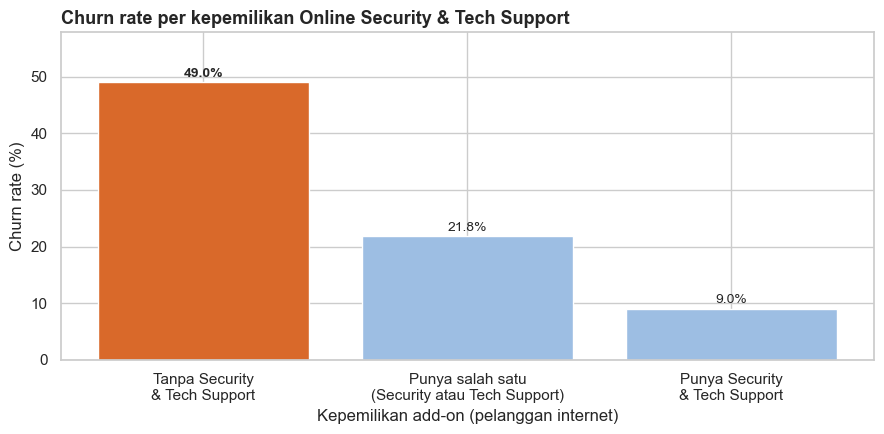

Kombinasi Security × Tech Support: chi2 = 693.1 | p-value = 3.14e-151 | Cramér's V = 0.355 (sedang)
→ Tolak H0: ada hubungan signifikan dengan churn


In [80]:
fig, ax = plt.subplots(figsize=(9, 4.5))
label_addon = {"Tidak punya keduanya": "Tanpa Security\n& Tech Support",
               "Punya salah satu": "Punya salah satu\n(Security atau Tech Support)",
               "Punya keduanya": "Punya Security\n& Tech Support"}
bar_rates(addon_tbl["Churn_Rate_pct"].rename(index=label_addon),
          "Churn rate per kepemilikan Online Security & Tech Support",
          "Kepemilikan add-on (pelanggan internet)", ax=ax)
plt.tight_layout()
plt.savefig("plot_09_rq3_addons.png", dpi=150, bbox_inches="tight")
plt.show()

_ = chi2_report(internet, "AddOns", label="Kombinasi Security × Tech Support")

**Insight Online Security × Tech Support:**
- Pelanggan **tanpa Online Security maupun Tech Support** adalah kelompok **paling besar (2.553 pelanggan atau 46,3% pelanggan internet)** sekaligus memiliki churn rate **paling tinggi (49,0%)**. Kelompok ini menyumbang **1.250 churner atau 71,2% dari churn pelanggan internet**.
- Sebaliknya, pelanggan yang **punya keduanya** adalah kelompok **paling kecil (1.096 pelanggan atau 19,9%)** dengan churn rate **paling rendah (9,0%)**, dan hanya menyumbang 99 churner (5,6%). Churn kelompok tanpa add-on sekitar **5 kali lebih tinggi**.
- Pelanggan yang **punya salah satu** berada di tengah (1.863 pelanggan, churn 21,8%, 23,2% churn). Semakin banyak add-on yang dimiliki, semakin rendah churn-nya.
- Chi-square menunjukkan hubungan yang **signifikan** (p < 0,001) dengan **Cramér's V = 0,36 (sedang)**.

## 8.4 Jenis Internet dan Tier Tagihan

In [81]:
internet_tbl = churn_table(df_clean, "InternetService").sort_values("Churn_Rate_pct", ascending=False)
charge_tbl = churn_table(df_clean, "MonthlyChargeGroup").sort_values("Churn_Rate_pct", ascending=False)
display(internet_tbl)
display(charge_tbl)

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
InternetService,,,,
Fiber optic,3096,1297,41.90,69.40
DSL,2416,459,19.00,24.60
No,1520,113,7.40,6.00


,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
MonthlyChargeGroup,,,,
High,2342,798,34.10,42.70
Medium,2345,698,29.80,37.30
Low,2345,373,15.90,20.00


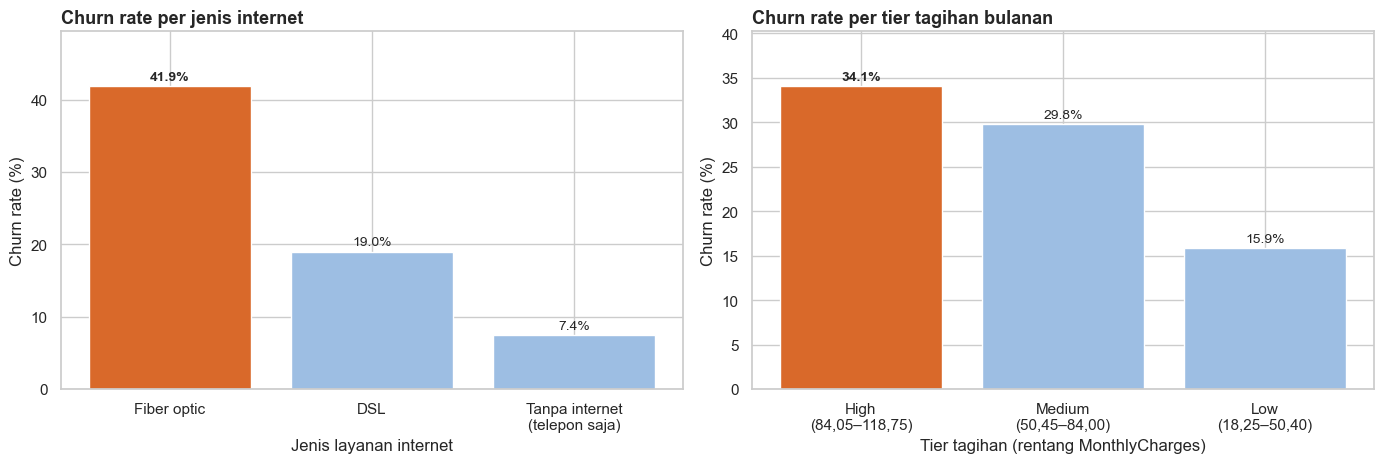

In [82]:
label_internet = {"Fiber optic": "Fiber optic", "DSL": "DSL",
                  "No": "Tanpa internet\n(telepon saja)"}
label_tier = {"High": "High\n(84,05–118,75)", "Medium": "Medium\n(50,45–84,00)",
              "Low": "Low\n(18,25–50,40)"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
bar_rates(internet_tbl["Churn_Rate_pct"].rename(index=label_internet),
          "Churn rate per jenis internet", "Jenis layanan internet", ax=axes[0])
bar_rates(charge_tbl["Churn_Rate_pct"].rename(index=label_tier),
          "Churn rate per tier tagihan bulanan", "Tier tagihan (rentang MonthlyCharges)", ax=axes[1])
plt.tight_layout()
plt.savefig("plot_10_rq3_internet_charge.png", dpi=150, bbox_inches="tight")
plt.show()

In [83]:
_ = chi2_report(df_clean, "InternetService")
_ = chi2_report(df_clean, "MonthlyChargeGroup")

InternetService: chi2 = 728.7 | p-value = 5.83e-159 | Cramér's V = 0.322 (sedang)
→ Tolak H0: ada hubungan signifikan dengan churn
MonthlyChargeGroup: chi2 = 216.5 | p-value = 9.76e-48 | Cramér's V = 0.175 (lemah)
→ Tolak H0: ada hubungan signifikan dengan churn


In [84]:
# Porsi pelanggan per jenis internet (sama seperti tabel di section 5.6)
vc = df_clean["InternetService"].value_counts()
porsi_internet = pd.DataFrame({"Jumlah": vc, "Persen (%)": (vc / len(df_clean) * 100).round(1)})
print("Porsi pelanggan per jenis internet (lihat juga section 5.6):")
display(porsi_internet)

print("\nKomposisi jenis internet di tiap tier tagihan:")
display(pd.crosstab(df_clean["MonthlyChargeGroup"], df_clean["InternetService"]))

Porsi pelanggan per jenis internet (lihat juga section 5.6):


,Jumlah,Persen (%)
InternetService,,
Fiber optic,3096,44.00
DSL,2416,34.40
No,1520,21.60



Komposisi jenis internet di tiap tier tagihan:


InternetService,DSL,Fiber optic,No
MonthlyChargeGroup,,,
Low,825,0,1520
Medium,1416,929,0
High,175,2167,0


**Insight Jenis Internet dan Tier Tagihan:**
- **Fiber Optic** adalah layanan dengan pelanggan **paling banyak (3.096 pelanggan atau 44,0%)** sekaligus churn rate **paling tinggi (41,9%)**, lebih dari dua kali lipat DSL. Fiber menyumbang **1.297 churner atau 69,4% dari seluruh churn** (Cramér's V = 0,32, sedang). Porsi pelanggan per jenis internet diambil dari tabel di section 5.6 dan ditampilkan ulang di atas.
- **DSL** memiliki jumlah pelanggan yang tidak jauh berbeda (2.416 pelanggan), tetapi churn rate-nya hanya **19,0%** dan menyumbang 459 churner (24,6%). Pelanggan **tanpa internet** adalah kelompok paling kecil (1.520 pelanggan) dengan churn paling rendah (**7,4%**, 113 churner).
- Namun, data tidak menjelaskan **mengapa** pelanggan Fiber lebih banyak churn, karena tidak ada data kualitas jaringan, gangguan, atau komplain. Karena itu, Fiber hanya dipakai untuk memahami profil pelanggan berisiko, bukan sebagai dasar rekomendasi.
- Untuk **tier tagihan**, jumlah pelanggan di setiap tier **hampir sama** (sekitar 2.345 pelanggan), sehingga perbedaan jumlah churner murni berasal dari perbedaan churn rate: **High 34,1%** (798 churner, 42,7%), Medium 29,8% (698 churner, 37,3%), dan **Low 15,9%** (373 churner, 20,0%). Hubungannya signifikan tetapi **lemah** (Cramér's V = 0,18), konsisten dengan RQ1.
- Tier tagihan dan jenis internet **sangat tumpang tindih**: 92,5% pelanggan tier High adalah pengguna Fiber (2.167 dari 2.342), sedangkan tier Low berisi seluruh pelanggan tanpa internet ditambah sebagian DSL. Artinya, sebagian besar perbedaan churn antar tier tagihan sebenarnya mencerminkan perbedaan jenis internet.

### Insight → Action → Impact (RQ3)
- **Insight:** dari 18 atribut, enam memiliki hubungan sedang dengan churn. Selain kontrak dan tenure (RQ2), dua atribut yang **bisa diubah oleh perusahaan** adalah **metode pembayaran** (e-check churn 53,7% di dalam month-to-month) dan **add-on** (tanpa security dan tech support churn 49,0% vs 9,0%). Atribut demografi lemah, dan gender tidak signifikan.
- **Action:**
  - **R2:** tawarkan insentif kepada pembayar e-check untuk **pindah ke autodebit**.
  - **R3:** berikan **trial gratis 3 bulan Online Security + Tech Support** kepada pelanggan internet yang belum memiliki keduanya.
- **Impact:** churn pembayar e-check month-to-month (53,7%) diarahkan mendekati pembayar otomatis (32,8–34,1%) (**G3a**), dan churn pelanggan tanpa add-on (49,0%) diarahkan mendekati pelanggan dengan minimal satu add-on (21,8%) (**G3b**). Rekomendasi lengkapnya dijelaskan di bagian 10.

# 9. RQ4: Risk Score dan Profil Pelanggan High-Risk

> Bisakah atribut terkuat digabung menjadi satu risk score? Seperti apa profil pelanggan high-risk, dan berapa porsi churn yang mereka sumbang? **(G4)**

**Cara membuat risk score:** setiap pelanggan mendapat **+1 poin** untuk setiap flag berikut. Keenam flag dipilih dari atribut yang terbukti berhubungan dengan churn di RQ2 dan RQ3:

| Flag | Dasar dari analisis sebelumnya |
|---|---|
| 1. Tenure 0–6 bulan | RQ2: churn tertinggi (53,3%) |
| 2. Kontrak month-to-month | RQ2: atribut terkuat (V = 0,41) |
| 3. Bayar Electronic check | RQ3: tetap tertinggi di dalam kontrak yang sama |
| 4. Tier tagihan High (≥ 84,05) | RQ1 & RQ3: pelanggan churn cenderung di tier tagihan lebih tinggi |
| 5. Tanpa Online Security | RQ3: V = 0,35 |
| 6. Tanpa Tech Support | RQ3: V = 0,34 |

Skor berkisar **0–6**, lalu dibagi menjadi tiga segmen: **High Risk** (5–6), **Medium Risk** (3–4), dan **Low Risk** (0–2).

**Kenapa bobotnya sama (masing-masing +1)?** Supaya skor mudah dipahami dan bisa dihitung langsung oleh tim retensi tanpa model.

**Kenapa InternetService (Fiber) tidak dijadikan flag?** Pertama, Fiber sangat tumpang tindih dengan tier tagihan High (92,5% pelanggan tier High adalah pengguna Fiber, lihat RQ3), sehingga memasukkan keduanya berarti menghitung hal yang sama dua kali. Kedua, Fiber adalah produk yang ingin dijual perusahaan, bukan sesuatu yang ingin dihindari.

## 9.1 Validasi Setiap Flag

In [85]:
FLAGS = {
    "Tenure 0–6 bulan": df_clean["tenure"] <= 6,
    "Kontrak month-to-month": df_clean["Contract"] == "Month-to-month",
    "Bayar Electronic check": df_clean["PaymentMethod"] == "Electronic check",
    "Tier tagihan High": df_clean["MonthlyChargeGroup"] == "High",
    "Tanpa Online Security": df_clean["OnlineSecurity"] == "No",
    "Tanpa Tech Support": df_clean["TechSupport"] == "No",
}

rows = []
for name, mask in FLAGS.items():
    rows.append({"Flag": name, "Jumlah pelanggan": int(mask.sum()),
                 "Churn jika YA (%)": round(df_clean.loc[mask, "ChurnFlag"].mean() * 100, 1),
                 "Churn jika TIDAK (%)": round(df_clean.loc[~mask, "ChurnFlag"].mean() * 100, 1)})
flag_tbl = pd.DataFrame(rows)
flag_tbl["Selisih (poin)"] = flag_tbl["Churn jika YA (%)"] - flag_tbl["Churn jika TIDAK (%)"]
display(flag_tbl)

,Flag,Jumlah pelanggan,Churn jika YA (%),Churn jika TIDAK (%),Selisih (poin)
0,Tenure 0–6 bulan,1470,53.30,19.50,33.80
1,Kontrak month-to-month,3875,42.70,6.80,35.90
2,Bayar Electronic check,2365,45.30,17.10,28.20
3,Tier tagihan High,2342,34.10,22.80,11.30
4,Tanpa Online Security,3497,41.80,11.50,30.30
5,Tanpa Tech Support,3472,41.60,11.90,29.70


**Insight Validasi Flag:**
- **Setiap flag menaikkan churn.** Pelanggan yang memiliki flag selalu memiliki churn rate lebih tinggi dibandingkan yang tidak memilikinya.
- Flag **Tenure 0–6 bulan** dimiliki oleh kelompok **paling kecil (1.470 pelanggan)**, tetapi churn-nya **paling tinggi (53,3%** vs 19,5% tanpa flag). Sebaliknya, flag **Month-to-month** dimiliki kelompok **paling besar (3.875 pelanggan)** dengan churn 42,7% vs 6,8%, menghasilkan **selisih terbesar (35,9 poin)**.
- Flag **Tanpa Online Security** (3.497 pelanggan) dan **Tanpa Tech Support** (3.472 pelanggan) mencakup jumlah pelanggan yang hampir sama besar dengan month-to-month, dengan selisih churn sekitar 30 poin. Flag **Electronic check** (2.365 pelanggan) memiliki selisih 28,2 poin.
- Flag **Tier tagihan High** mencakup 2.342 pelanggan, tetapi selisihnya **paling kecil (34,1% vs 22,8%, 11,3 poin)**, sesuai dengan efek tagihan yang kecil di RQ1 dan RQ3. Flag ini tetap dipakai sebagai pelengkap.

## 9.2 Risk Score

In [86]:
df_clean["RiskScore"] = sum(mask.astype(int) for mask in FLAGS.values())
df_clean["RiskSegment"] = pd.cut(df_clean["RiskScore"], bins=[-1, 2, 4, 6],
                                 labels=["Low Risk", "Medium Risk", "High Risk"])

score_tbl = churn_table(df_clean, "RiskScore").sort_values("Churn_Rate_pct", ascending=False)
display(score_tbl)

,Customers,Churned,Churn_Rate_pct,Share_of_Churners_pct
RiskScore,,,,
6,126,103,81.70,5.50
5,886,582,65.70,31.10
4,1197,569,47.50,30.40
3,1141,309,27.10,16.50
2,1252,203,16.20,10.90
1,1120,78,7.00,4.20
0,1310,25,1.90,1.30


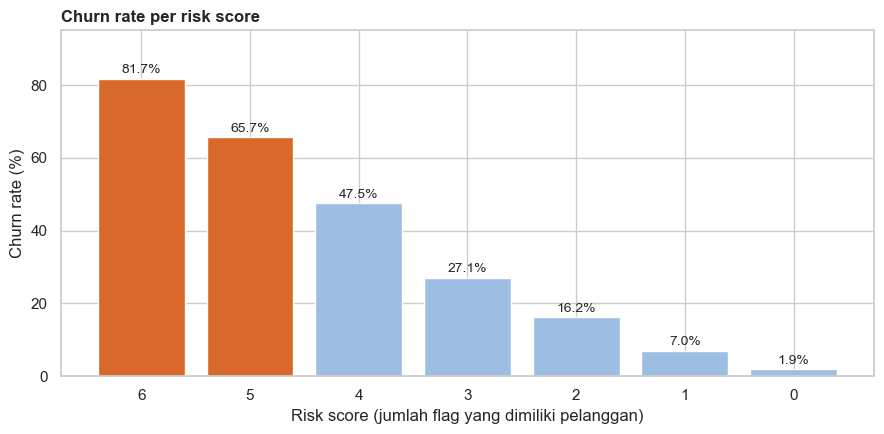

RiskScore: chi2 = 1,858.8 | p-value = 0.00e+00 | Cramér's V = 0.514 (kuat)
→ Tolak H0: ada hubungan signifikan dengan churn


In [87]:
fig, ax = plt.subplots(figsize=(9, 4.5))
s = score_tbl["Churn_Rate_pct"]
ax.bar(s.index.astype(str), s.values, color=[HI if i >= 5 else CTX for i in s.index])
for i, v in enumerate(s.values):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_title("Churn rate per risk score", fontweight="bold", loc="left")
ax.set_xlabel("Risk score (jumlah flag yang dimiliki pelanggan)"); ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, 95)
plt.tight_layout()
plt.savefig("plot_11_rq4_riskscore.png", dpi=150, bbox_inches="tight")
plt.show()

_ = chi2_report(df_clean, "RiskScore")

**Insight Risk Score:**
- Churn rate **naik konsisten di setiap tambahan flag**: dari **1,9%** pada pelanggan tanpa flag, menjadi 7,0% (1 flag), 16,2% (2), 27,1% (3), 47,5% (4), 65,7% (5), hingga **81,7%** pada pelanggan dengan keenam flag.
- Hubungan risk score dengan churn **kuat** (Cramér's V = **0,51**, p < 0,001), **lebih kuat daripada atribut tunggal mana pun** (atribut terkuat di RQ3 adalah Contract dengan V = 0,41). Artinya, menggabungkan keenam flag memberi gambaran risiko yang lebih baik daripada melihat satu atribut saja.

## 9.3 Segmen Risiko

In [88]:
seg_tbl = churn_table(df_clean, "RiskSegment").reindex(["High Risk", "Medium Risk", "Low Risk"])
seg_tbl.insert(1, "Share_of_Customers_pct", (seg_tbl["Customers"] / len(df_clean) * 100).round(1))
display(seg_tbl)

,Customers,Share_of_Customers_pct,Churned,Churn_Rate_pct,Share_of_Churners_pct
RiskSegment,,,,,
High Risk,1012,14.40,685,67.70,36.70
Medium Risk,2338,33.20,878,37.60,47.00
Low Risk,3682,52.40,306,8.30,16.40


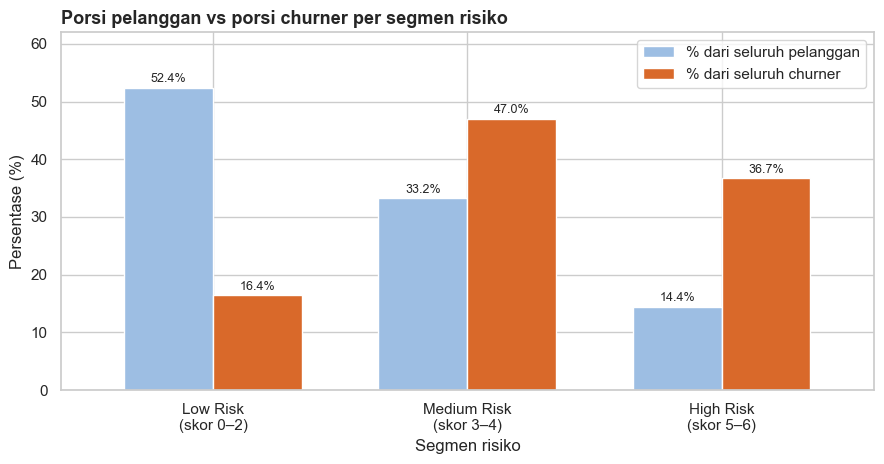

RiskSegment: chi2 = 1,650.4 | p-value = 0.00e+00 | Cramér's V = 0.484 (sedang)
→ Tolak H0: ada hubungan signifikan dengan churn


In [89]:
label_segmen = {"High Risk": "High Risk\n(skor 5–6)", "Medium Risk": "Medium Risk\n(skor 3–4)",
                "Low Risk": "Low Risk\n(skor 0–2)"}

fig, ax = plt.subplots(figsize=(9, 4.8))
(seg_tbl[["Share_of_Customers_pct", "Share_of_Churners_pct"]]
    .sort_values("Share_of_Customers_pct", ascending=False)
    .rename(index=label_segmen,
            columns={"Share_of_Customers_pct": "% dari seluruh pelanggan",
                     "Share_of_Churners_pct": "% dari seluruh churner"})
    .plot(kind="bar", color=[CTX, HI], rot=0, ax=ax, width=0.7))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", fontsize=9, padding=2)
ax.set_title("Porsi pelanggan vs porsi churner per segmen risiko", fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Persentase (%)"); ax.set_xlabel("Segmen risiko")
ax.set_ylim(0, 62)
plt.tight_layout()
plt.savefig("plot_12_rq4_segment.png", dpi=150, bbox_inches="tight")
plt.show()

_ = chi2_report(df_clean, "RiskSegment")

**Insight Segmen Risiko:**
- **Low Risk** memiliki jumlah pelanggan **paling banyak** (3.682 pelanggan atau 52,4%), tetapi churn rate-nya **paling rendah**, yaitu hanya **8,3%**. Walaupun berisi lebih dari separuh pelanggan, kelompok ini hanya menyumbang 306 churner (16,4% dari seluruh churn).
- Sebaliknya, **High Risk** memiliki jumlah pelanggan **paling sedikit** (1.012 pelanggan atau 14,4%), tetapi churn rate-nya **paling tinggi**, yaitu **67,7%**, sekitar **8 kali lebih tinggi** dibandingkan Low Risk. Artinya, dua dari tiga pelanggan High Risk berhenti berlangganan, dan kelompok kecil ini menyumbang 685 churner (36,7% dari seluruh churn).
- **Medium Risk** berada di tengah dari sisi churn rate (**37,6%**), tetapi karena jumlah pelanggannya cukup besar (2.338 pelanggan atau 33,2%), kelompok ini justru menyumbang **jumlah churner terbanyak**, yaitu 878 churner (**47,0%** dari seluruh churn).
- Jika digabung, **High dan Medium Risk** hanya mencakup **47,6% pelanggan**, tetapi menyumbang **83,6% dari seluruh churn**. Karena itu, tim retensi cukup memprioritaskan kedua kelompok ini, dimulai dari High Risk (churn rate tertinggi), lalu Medium Risk (jumlah churner terbanyak).
- Batas segmen dipilih berdasarkan lonjakan churn: skor 5 ke atas memiliki churn di atas 65%, skor 3–4 berada di 27–48%, dan skor 0–2 di bawah 17%.

### 9.3.1 Profil Setiap Segmen (Diagnostik)

Untuk menjawab **mengapa** churn High Risk jauh lebih tinggi dan mengapa Low Risk tetap rendah walaupun jumlahnya paling banyak, karakteristik ketiga segmen dibandingkan secara berdampingan.

In [90]:
seg_profile = df_clean.groupby("RiskSegment", observed=True).agg(
    Pelanggan=("ChurnFlag", "size"),
    Churn_rate_pct=("ChurnFlag", lambda s: s.mean() * 100),
    Rata_rata_flag=("RiskScore", "mean"),
    Median_tenure_bulan=("tenure", "median"),
    Month_to_month_pct=("Contract", lambda s: (s == "Month-to-month").mean() * 100),
    Kontrak_2_tahun_pct=("Contract", lambda s: (s == "Two year").mean() * 100),
    E_check_pct=("PaymentMethod", lambda s: (s == "Electronic check").mean() * 100),
    Auto_pay_pct=("PaymentMethod", lambda s: s.str.contains("automatic").mean() * 100),
    Fiber_pct=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
    Tanpa_internet_pct=("InternetService", lambda s: (s == "No").mean() * 100),
).reindex(["High Risk", "Medium Risk", "Low Risk"]).T

seg_profile = seg_profile.rename(index={
    "Pelanggan": "Jumlah pelanggan",
    "Churn_rate_pct": "Churn rate (%)",
    "Rata_rata_flag": "Rata-rata jumlah flag",
    "Median_tenure_bulan": "Median tenure (bulan)",
    "Month_to_month_pct": "Kontrak month-to-month (%)",
    "Kontrak_2_tahun_pct": "Kontrak 2 tahun (%)",
    "E_check_pct": "Bayar Electronic check (%)",
    "Auto_pay_pct": "Bayar otomatis / auto-pay (%)",
    "Fiber_pct": "Pengguna Fiber optic (%)",
    "Tanpa_internet_pct": "Tanpa internet / telepon saja (%)",
})

display(seg_profile.style.format("{:,.1f}").format(
    "{:,.0f}", subset=pd.IndexSlice[["Jumlah pelanggan", "Median tenure (bulan)"], :]))

RiskSegment,High Risk,Medium Risk,Low Risk
Jumlah pelanggan,"1,012","2,338","3,682"
Churn rate (%),67.7,37.6,8.3
Rata-rata jumlah flag,5.1,3.5,1.0
Median tenure (bulan),4,21,45
Kontrak month-to-month (%),100.0,83.5,24.7
Kontrak 2 tahun (%),0.0,4.3,43.0
Bayar Electronic check (%),96.5,45.9,8.5
Bayar otomatis / auto-pay (%),1.8,35.9,59.9
Pengguna Fiber optic (%),84.7,64.9,19.6
Tanpa internet / telepon saja (%),0.0,1.3,40.4


**Insight Profil Segmen:**
- **Mengapa High Risk churn-nya tinggi (67,7%)?** Karena faktor risikonya **menumpuk pada pelanggan yang sama**. Rata-rata pelanggan High Risk memiliki **5,1 flag**: mereka masih baru (median tenure **4 bulan**), **100%** berkontrak month-to-month, **96,5%** membayar manual dengan Electronic Check, dan hampir tidak ada yang memakai auto-pay (1,8%). Tidak ada satu pun faktor yang "mengikat" mereka untuk tetap berlangganan.
- **Mengapa Low Risk churn-nya rendah (8,3%) walaupun jumlahnya paling banyak?** Pelanggan Low Risk sudah **lama berlangganan** (median **45 bulan**), **43,0%** terikat kontrak 2 tahun, **59,9%** sudah memakai auto-pay, dan **40,4%** hanya memakai layanan telepon tanpa internet (layanan yang lebih sederhana). Mereka adalah pelanggan yang sudah "lengket".
- **Medium Risk** berada di antara keduanya: sebagian besar masih month-to-month (83,5%), tetapi sudah lebih lama berlangganan (median 21 bulan) dan sebagian sudah memakai auto-pay (35,9%).
- **Diagnosis:** churn tidak disebabkan oleh satu faktor saja, melainkan oleh **kombinasi** tidak adanya ikatan kontrak, pembayaran manual, dan tidak adanya layanan pelindung pada pelanggan baru. Karena itu, rekomendasi di bagian 10 menangani setiap faktor tersebut secara bersamaan.

## 9.4 Profil Pelanggan High Risk

In [91]:
high = df_clean[df_clean["RiskSegment"] == "High Risk"]
profile = {
    "Jumlah pelanggan": len(high),
    "Churn rate (%)": round(high["ChurnFlag"].mean() * 100, 1),
    "Tenure 0–6 bulan (%)": round((high["tenure"] <= 6).mean() * 100, 1),
    "Month-to-month (%)": round((high["Contract"] == "Month-to-month").mean() * 100, 1),
    "Electronic check (%)": round((high["PaymentMethod"] == "Electronic check").mean() * 100, 1),
    "Tier tagihan High (%)": round((high["MonthlyChargeGroup"] == "High").mean() * 100, 1),
    "Tanpa Online Security (%)": round((high["OnlineSecurity"] == "No").mean() * 100, 1),
    "Tanpa Tech Support (%)": round((high["TechSupport"] == "No").mean() * 100, 1),
    "Fiber optic (%)": round((high["InternetService"] == "Fiber optic").mean() * 100, 1),
    "Median tenure (bulan)": high["tenure"].median(),
}
display(pd.Series(profile, name="High Risk").to_frame().style.format("{:,.1f}").format("{:,.0f}", subset=pd.IndexSlice[["Jumlah pelanggan", "Median tenure (bulan)"], :]))

,High Risk
Jumlah pelanggan,"1,012"
Churn rate (%),67.7
Tenure 0–6 bulan (%),59.9
Month-to-month (%),100.0
Electronic check (%),96.5
Tier tagihan High (%),58.8
Tanpa Online Security (%),98.8
Tanpa Tech Support (%),98.4
Fiber optic (%),84.7
Median tenure (bulan),4


**Insight Profil High Risk:**
- Pelanggan High Risk yang khas adalah pelanggan **baru** (median tenure **4 bulan**; 59,9% masih di 6 bulan pertama) dengan **kontrak month-to-month (100%)**, **membayar dengan Electronic check (96,5%)**, dan **tidak memiliki Online Security (98,8%) maupun Tech Support (98,4%)**.
- Sebagian besar menggunakan **Fiber optic (84,7%)**, dan 58,8% berada di tier tagihan High.
- Profil ini cocok dengan ketiga tawaran retensi sekaligus: hampir semua pelanggan High Risk memenuhi syarat untuk upgrade kontrak (R1), pindah ke autodebit (R2), dan trial security + tech support (R3).

### Insight → Action → Impact (RQ4)
- **Insight:** keenam flag dapat digabung menjadi satu risk score yang hubungannya dengan churn **kuat** (V = 0,51), lebih kuat dari atribut tunggal mana pun. Segmen **High Risk** hanya **14,4% pelanggan**, tetapi churn-nya **67,7%** dan menyumbang **36,7% churn**.
- **Action (R4):** hitung risk score untuk seluruh pelanggan **setiap bulan**, dan jadikan sebagai **daftar prioritas** tim retensi. Pelanggan High Risk dihubungi lebih dulu, dengan setengah dari mereka dijadikan grup pembanding (tidak ditawari) selama pilot untuk mengukur efek tawaran yang sebenarnya.
- **Impact (G4):** seluruh **1.012 pelanggan High Risk** dihubungi dalam **30 hari pertama**, dan churn kelompok ini diarahkan mendekati Medium Risk (37,6%). Hasil pilot dipakai untuk mengukur efek tawaran yang sebenarnya.

# 10. Rekomendasi: SambungHome SHIELD

Berdasarkan RQ1–RQ4, rekomendasi disusun menjadi satu program bernama **SambungHome SHIELD**, yaitu **empat lapis perlindungan dari churn**. Setiap lapis menangani satu faktor risiko yang terbukti dalam analisis, dan setiap lapis terhubung ke satu goal.

| Lapis | Nama | Faktor yang ditangani | Kelompok sasaran | Goal |
|---|---|---|---|---|
| 🔒 **1** | **Paket Komitmen** | Tidak ada ikatan kontrak | Pelanggan baru month-to-month (1.413) | G2 |
| 💳 **2** | **Auto-Pay Switch** | Pembayaran manual | Pembayar e-check month-to-month (1.850) | G3a |
| 🛡️ **3** | **Protection Starter Pack** | Tidak ada layanan pelindung | Pelanggan internet tanpa Online Security & Tech Support (2.553) | G3b |
| 🎯 **4** | **Risk Score Priority List** | Prioritas penanganan | Pelanggan High Risk (1.012), lalu Medium Risk | G4 |

Rekomendasi disusun mengikuti **momen kunci dalam perjalanan pelanggan baru**: hari pemasangan, sebelum tagihan pertama (hari ke-25), dan akhir masa kritis (bulan ke-6). Momen ini dipilih karena churn paling tinggi terjadi di bulan pertama (62,0%, bagian 7.1.1).

## 10.1 🔒 Lapis 1 · Paket Komitmen (→ G2)

| SMART | Penjelasan |
|---|---|
| **Specific** | Pelanggan baru (0–6 bulan) dengan kontrak month-to-month. Tawaran: upgrade ke **kontrak 1 tahun** dengan **diskon 15% tagihan bulanan selama 12 bulan** dan **gratis biaya pemasangan**. Ditawarkan oleh teknisi saat pemasangan dan diulang oleh CS di hari ke-25. |
| **Measurable** | Persentase pelanggan yang upgrade; churn kelompok yang ditawari dibandingkan kelompok pembanding. Arah target: churn 55,2% mendekati rata-rata month-to-month (42,7%). |
| **Achievable** | Dijalankan oleh teknisi dan tim CS yang sudah bertemu pelanggan saat pemasangan, tanpa sistem baru. |
| **Relevant** | Contract adalah atribut terkuat (Cramér's V = 0,41). Pelanggan baru month-to-month churn 55,2% dan menyumbang 41,7% dari seluruh churn (RQ2). |
| **Time-bound** | Tawaran berlaku sampai bulan ke-6 masa berlangganan; dievaluasi pada bulan ke-3 program. |

## 10.2 💳 Lapis 2 · Auto-Pay Switch (→ G3a)

| SMART | Penjelasan |
|---|---|
| **Specific** | Pembayar Electronic Check dengan kontrak month-to-month. Tawaran: **diskon 5% tagihan selama 6 bulan** jika mendaftar auto-pay (bank transfer atau kartu kredit). Pendaftaran auto-pay juga ditawarkan sejak hari pemasangan. |
| **Measurable** | Persentase pelanggan yang pindah ke auto-pay; churn kelompok yang ditawari dibandingkan kelompok pembanding. Arah target: churn 53,7% mendekati pembayar otomatis (32,8–34,1%). |
| **Achievable** | Notifikasi melalui aplikasi/SMS 5 hari sebelum jatuh tempo, disertai tautan pendaftaran auto-pay. |
| **Relevant** | Pada kontrak yang sama (month-to-month), churn e-check 53,7% dibandingkan metode otomatis 32,8–34,1% (RQ3). |
| **Time-bound** | Dikirim setiap siklus tagihan selama 3 bulan pertama program. |

## 10.3 🛡️ Lapis 3 · Protection Starter Pack (→ G3b)

| SMART | Penjelasan |
|---|---|
| **Specific** | Pelanggan internet tanpa Online Security dan Tech Support. Tawaran: **gratis 3 bulan Online Security + Tech Support**, aktif sejak pemasangan, ditambah *check-in call* oleh teknisi pada hari ke-7 dan ke-30. |
| **Measurable** | Persentase pelanggan yang melanjutkan langganan setelah masa trial; churn kelompok yang ditawari dibandingkan kelompok pembanding. Arah target: churn 49,0% mendekati pelanggan dengan minimal satu add-on (21,8%). |
| **Achievable** | Diaktifkan oleh teknisi saat pemasangan; *check-in* memakai tim Tech Support yang sudah ada. |
| **Relevant** | Pelanggan tanpa keduanya churn 49,0% dibandingkan 9,0% pada pelanggan yang memiliki keduanya, dan menyumbang 71,2% churn pelanggan internet (RQ3). |
| **Time-bound** | Trial 3 bulan; penawaran lanjutan berbayar dikirim pada minggu ke-11. |

## 10.4 🎯 Lapis 4 · Risk Score Priority List (→ G4) 

| SMART | Penjelasan |
|---|---|
| **Specific** | Tim retensi menghubungi pelanggan **High Risk** lebih dulu, lalu **Medium Risk**, dan menawarkan Lapis 1–3 sesuai kondisi masing-masing pelanggan. |
| **Measurable** | Jumlah pelanggan High Risk yang dihubungi (seluruh 1.012 pelanggan dalam 30 hari). Arah target: churn High Risk 67,7% mendekati Medium Risk (37,6%). |
| **Achievable** | Risk score hanya penjumlahan 6 flag, sehingga dapat dihitung di Excel atau dashboard tanpa model. |
| **Relevant** | High + Medium Risk mencakup 47,6% pelanggan, tetapi menyumbang 83,6% seluruh churn (RQ4). |
| **Time-bound** | Risk score diperbarui setiap awal bulan. |

> Besaran diskon (15% dan 5%) merupakan usulan awal dan perlu dikonfirmasi bersama tim Finance, karena data biaya tidak tersedia di dataset.

## 10.5 Timeline Implementasi (12 Bulan)

| Fase | Bulan | Kegiatan |
|---|---|---|
| **Pilot** | 1–3 | Pelanggan High Risk dibagi acak menjadi *offered group* (menerima Lapis 1–3) dan *comparison group* (tidak menerima tawaran). |
| **Checkpoint** | 3 | Program dilanjutkan jika churn *offered group* lebih rendah daripada *comparison group*. Jika tidak, bentuk tawaran disesuaikan terlebih dahulu. |
| **Perluasan** | 4–6 | Program diperluas ke pelanggan Medium Risk. |
| **Penerapan penuh** | 7–12 | Seluruh pelanggan yang memenuhi syarat; KPI dipantau setiap bulan melalui dashboard. |

**KPI yang dipantau setiap bulan:**
- Churn rate keseluruhan (baseline 26,6%)
- Churn rate setiap kelompok sasaran dibandingkan benchmark internalnya
- Persentase penerimaan setiap tawaran (upgrade kontrak, pindah auto-pay, lanjut add-on)
- Selisih churn *offered group* dan *comparison group*
- Jumlah pelanggan High Risk yang sudah dihubungi

# 11. Kesimpulan

| RQ | Jawaban |
|---|---|
| **RQ1** | **1.869 dari 7.032 pelanggan (26,6%) churn**, atau sekitar 1 dari 4 pelanggan. Pelanggan churn jauh **lebih baru** (median tenure 10 vs 38 bulan, efek sedang) dan berada di tier tagihan sedikit lebih tinggi (efek kecil). |
| **RQ2** | Churn paling tinggi di **6 bulan pertama (53,3%)** dan pada kontrak **month-to-month (42,7%, 88,6% dari seluruh churn)**. Segmen paling berisiko adalah pelanggan baru month-to-month: churn **55,2%**, menyumbang **41,7%** seluruh churn. Kontrak 1–2 tahun tetap rendah di semua tahap tenure. |
| **RQ3** | Dari 18 atribut, **enam** memiliki hubungan sedang (V ≥ 0,30). Dua yang bisa diubah perusahaan: **e-check** (tetap tertinggi di dalam month-to-month, 53,7%) dan **tanpa Online Security & Tech Support** (49,0% vs 9,0%). Gender dan PhoneService tidak berhubungan dengan churn. |
| **RQ4** | Risk score 6 flag memiliki hubungan **kuat** dengan churn (V = 0,51). **1.012 pelanggan High Risk (14,4%)** memiliki churn **67,7%** dan menyumbang **36,7%** seluruh churn. High + Medium Risk = 47,6% pelanggan, tetapi 83,6% churn. |
| **Rekomendasi** | **SambungHome SHIELD**: Paket Komitmen, Auto-Pay Switch, Protection Starter Pack, dan Risk Score Priority List. Setiap kelompok berisiko diarahkan mendekati benchmark internalnya, dengan efek sebenarnya diukur melalui pilot 3 bulan. |

# 12. Limitasi dan Langkah Selanjutnya

| Limitasi | Langkah selanjutnya |
|---|---|
| Data adalah sampel publik (IBM), bukan data internal perusahaan | Jalankan ulang notebook ini dengan data pelanggan perusahaan |
| Periode `MonthlyCharges` tidak dijelaskan di sumber data, sehingga dampak tidak dihitung dalam nilai uang | Hitung dampak pendapatan setelah memakai data tagihan internal yang periodenya jelas |
| Hasil berupa asosiasi, bukan sebab-akibat | Uji lewat pilot dengan *offered group* dan *comparison group* |
| Besarnya penurunan churn dari setiap tawaran belum diketahui | Ukur langsung saat pilot, lalu tetapkan target angka yang lebih spesifik |
| Biaya tawaran (diskon, trial) tidak tersedia | Hitung biaya bersama tim Finance sebelum penerapan penuh |
| Tidak ada data kualitas jaringan, gangguan, atau komplain, sehingga tingginya churn Fiber belum terjelaskan | Tambahkan data tersebut dan lakukan analisis khusus pelanggan Fiber |
| Data hanya satu snapshot tanpa histori | Perbarui risk score setiap bulan melalui dashboard |
| Risk score memakai bobot yang sama untuk setiap flag | Evaluasi ulang flag dan batas segmen dengan data hasil pilot |

## Export Data Final

Dataset final berisi data clean beserta kolom hasil feature engineering (`ChurnFlag`, `SeniorCitizenLabel`, `TenureGroup`, `MonthlyChargeGroup`) dan hasil risk scoring (`RiskScore`, `RiskSegment`). Dataset ini digunakan untuk pembuatan dashboard.

In [92]:
df_clean.to_csv("Telco_Customer_Churn_Final(remedy ver 4).csv", index=False, encoding="utf-8-sig")

print("Dataset berhasil disimpan sebagai 'Telco_Customer_Churn_Final(remedy ver 4).csv'")
print("Jumlah baris:", len(df_clean), "| Jumlah kolom:", df_clean.shape[1])
print("Kolom:", list(df_clean.columns))

Dataset berhasil disimpan sebagai 'Telco_Customer_Churn_Final(remedy ver 4).csv'
Jumlah baris: 7032 | Jumlah kolom: 27
Kolom: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'ChurnFlag', 'SeniorCitizenLabel', 'TenureGroup', 'MonthlyChargeGroup', 'RiskScore', 'RiskSegment']
